# Анализ снижения активности клиентов банка

## Блок I. Задача и аудит

### 1. Задача и данные

В учебном банке «Меридиан» сравниваем использование карт за 2024 год и январь-июнь 2025 года. Периоды делим на 12 и 6 месяцев; отдельно сравним первые полугодия. Справочник содержит действующих клиентов на 30.06.2025, операции связаны с ним по client_id.

Для кампании нужны 3-5 непересекающихся групп: от 150 человек в каждой, до 2000 суммарно, только с согласием. В этой копии завершены аудит, обработка, анализ и выбор групп. Результаты сохраняются в корне проекта и data/processed; исходные CSV читаются из data/raw.

| Таблица | Поля и смысл |
|---|---|
| clients | client_id: ключ; birth_date: рождение; gender: пол; city: город; segment: сегмент |
| clients | loyalty_tier: Базовый, Серебро, Золото, Платина; card_type: тип текущей карты |
| clients | registration_date: приход в банк; card_open_date: открытие текущей карты; app_last_login: месяц входа |
| clients | monthly_income: доход в рублях; income_source: источник зарплаты; has_mobile_app: приложение |
| clients | satisfaction_score: порядковая оценка 1-5; branch_code: код отделения; marketing_opt_in: согласие |
| transactions | txn_id: ключ; client_id: клиент; txn_datetime: дата и время; amount: сумма в currency |
| transactions | category: вид траты; mcc_code: код торговой точки; channel: канал; status: результат |

Карта означает пластик, Токен означает оплату телефоном или часами, СБП и Онлайн-банк считаются отдельными каналами. ID и коды не являются числами для арифметики. Оценку и лояльность рассматриваем как порядковые признаки. Истории изменений клиентских признаков и прежних карт нет.

### 2.1. Источники и окружение

In [1]:
import sys
import hashlib
from pathlib import Path
import pandas as pd
import numpy as np

project_root = Path.cwd()
if not (project_root / "data" / "raw").is_dir():
    project_root = project_root.parent
output_dir = project_root
output_dir.mkdir(exist_ok=True)
raw_dir = project_root / "data" / "raw"
required_files = [project_root / "pyproject.toml", raw_dir / "clients.csv", raw_dir / "transactions.csv"]
missing_files = [str(path) for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError("Запустите ноутбук из корня проекта. Не найдены: " + ", ".join(missing_files))

print("Python:", sys.executable)
print("Версия Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("Проект:", project_root)
print("Python из .venv проекта:", Path(sys.executable).resolve().parent == project_root / ".venv" / "Scripts")

source_hashes = {}
for filename in ["clients.csv", "transactions.csv"]:
    path = raw_dir / filename
    source_hashes[filename] = hashlib.sha256(path.read_bytes()).hexdigest()
    print(filename, path.stat().st_size, "байт")
    print("SHA-256:", source_hashes[filename])

Python: D:\DS_SBER\LAB_1\.venv\Scripts\python.exe
Версия Python: 3.14.4
pandas: 3.1.0
Проект: D:\DS_SBER\LAB_1
Python из .venv проекта: True
clients.csv 1061740 байт
SHA-256: d778cabc9a4d65de6aa6cfcbcf4c57d612129ffd5f8091a170d37b19429b0bbe
transactions.csv 47659568 байт
SHA-256: ad3a4347cd163d8d6e08da12ff6b2182b42fdf006b7db0bd6bd5a03acd9b2e7d


Используется окружение проекта. Для двух исходных CSV сохранены размер и SHA-256; эти значения сверим после обработки.

### 2.2. Форматы и загрузка

In [2]:
for filename, encoding in [("clients.csv", "utf-8-sig"), ("transactions.csv", "cp1251")]:
    print(f"\n{filename}; кодировка {encoding}")
    with (raw_dir / filename).open(encoding=encoding) as file:
        for _ in range(3):
            print(file.readline().rstrip("\n"))

clients_raw = pd.read_csv(raw_dir / "clients.csv", sep=",", encoding="utf-8-sig",
                          dtype="string", keep_default_na=False)
transactions_raw = pd.read_csv(raw_dir / "transactions.csv", sep=";", encoding="cp1251",
                               dtype="string", keep_default_na=False)

raw_tables = {"clients": clients_raw, "transactions": transactions_raw}
raw_fingerprints = {}
for name, df in raw_tables.items():
    raw_fingerprints[name] = hashlib.sha256(pd.util.hash_pandas_object(df, index=True).values.tobytes()).hexdigest()
    print(f"\n{name}: {df.shape[0]} строк, {df.shape[1]} столбцов")
    print("Столбцы:", df.columns.tolist())
    display(pd.concat([df.head(3), df.sample(3, random_state=42)]))


clients.csv; кодировка utf-8-sig
client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
C003407,1964-09-12,М,Москва,Премиальный,Серебро,Премиальная,20.06.2020,20.06.2022,Зарплата в нашем банке,108600.0,Да,2024-12,5,00395,Да
C003983,1965-08-21,М,Новосибирск,Массовый,Базовый,Кредитная,23.07.2016,30.07.2016,Не указан,65200.0,Да,2024-01,,00342,Да

transactions.csv; кодировка cp1251
txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status
990023;C005169;2023-11-23 10:48:18;1430,95;RUB;АЗС;5541;Карта;успешно
990111;C003522;2023-11-25 11:28:29;311,71;RUB;Продукты;5411;Онлайн-банк;успешно



clients: 5723 строк, 16 столбцов
Столбцы: ['client_id', 'birth_date', 'gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'registration_date', 'card_open_date', 'income_source', 'monthly_income', 'has_mobile_app', 'app_last_login', 'satisfaction_score', 'branch_code', 'marketing_opt_in']


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C003407,1964-09-12,М,Москва,Премиальный,Серебро,Премиальная,20.06.2020,20.06.2022,Зарплата в нашем банке,108600.0,Да,2024-12,5,00395,Да
1,C003983,1965-08-21,М,Новосибирск,Массовый,Базовый,Кредитная,23.07.2016,30.07.2016,Не указан,65200.0,Да,2024-01,,00342,Да
2,C000830,1984-02-16,Ж,Новосибирск,Премиальный,Золото,Дебетовая,10.02.2017,30.10.2018,Зарплата в другом банке,167800.0,Да,2024-01,3,00265,Да
1600,C000103,1974-11-05,Ж,Казань,Зарплатный,Базовый,Дебетовая,18.01.2015,04.03.2017,Зарплата в нашем банке,67600.0,Да,2025-06,,00383,Да
1121,C004302,1952-08-26,Ж,Москва,Премиальный,Серебро,Кредитная,15.10.2015,02.03.2019,Зарплата в нашем банке,189100.0,Нет,,3,00605,Да
4329,C000739,1982-03-13,М,г.Екатеринбург,Массовый,Базовый,Кредитная,06.09.2015,01.09.2021,Зарплата в нашем банке,37700.0,Да,2024-06,3,00439,Да



transactions: 616197 строк, 9 столбцов
Столбцы: ['txn_id', 'client_id', 'txn_datetime', 'amount', 'currency', 'category', 'mcc_code', 'channel', 'status']


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990023,C005169,2023-11-23 10:48:18,"1430,95",RUB,АЗС,5541,Карта,успешно
1,990111,C003522,2023-11-25 11:28:29,"311,71",RUB,Продукты,5411,Онлайн-банк,успешно
2,990017,C000223,2023-12-12 20:10:16,"213,46",RUB,Онлайн-сервисы,5815,Карта,успешно
3996,103975,C002318,2024-01-05 18:02:37,"256,59",RUB,Онлайн-сервисы,5815,Токен,успешно
197639,297091,C003435,2024-06-24 09:20:06,"680,76",RUB,Онлайн-сервисы,5815,Карта,успешно
602764,706144,C000918,2025-06-18 12:30:13,"1978,41",RUB,Развлечения и досуг,7832,СБП,успешно


В clients_raw 5723 строки, в transactions_raw 616197. У клиентов UTF-8 и разделитель-запятая, у операций Windows-1251, точка с запятой и десятичная запятая. Все поля прочитаны текстом, ведущие нули в кодах сохранены. Показаны первые и случайные строки; raw дальше не меняется.

### 2.3. Заполненность и значения

In [3]:
profiles = {}
for name, df in raw_tables.items():
    print(f"\n{name}: {len(df)} строк, {df.shape[1]} столбцов")
    summary = []
    for col in df.columns:
        s = df[col]
        stripped = s.str.strip()
        valid = s[stripped.ne("")]
        summary.append({
            "Признак": col, "Тип": str(s.dtype),
            "Пустых": int(s.eq("").sum()),
            "Только пробелы": int((s.ne("") & stripped.eq("")).sum()),
            "Пустых, %": round(stripped.eq("").mean() * 100, 2),
            "Пробелы по краям": int(s.ne(stripped).sum()),
            "Уникальных непустых": valid.nunique(),
            "Примеры значений": valid.drop_duplicates().head(3).tolist()
        })
    profiles[name] = pd.DataFrame(summary).set_index("Признак")
    with pd.option_context("display.max_colwidth", None):
        display(profiles[name])


clients: 5723 строк, 16 столбцов


,Тип,Пустых,Только пробелы,"Пустых, %",Пробелы по краям,Уникальных непустых,Примеры значений
Признак,,,,,,,
client_id,string,0,0,0.00,0,5668,"[C003407, C003983, C000830]"
birth_date,string,0,0,0.00,0,4850,"[1964-09-12, 1965-08-21, 1984-02-16]"
gender,string,0,0,0.00,0,2,"[М, Ж]"
city,string,0,0,0.00,163,17,"[Москва, Новосибирск, Екатеринбург]"
segment,string,0,0,0.00,0,4,"[Премиальный, Массовый, Зарплатный]"
loyalty_tier,string,0,0,0.00,0,4,"[Серебро, Базовый, Золото]"
card_type,string,0,0,0.00,0,3,"[Премиальная, Кредитная, Дебетовая]"
registration_date,string,0,0,0.00,0,3243,"[20.06.2020, 23.07.2016, 10.02.2017]"
card_open_date,string,0,0,0.00,0,2648,"[20.06.2022, 30.07.2016, 30.10.2018]"



transactions: 616197 строк, 9 столбцов


,Тип,Пустых,Только пробелы,"Пустых, %",Пробелы по краям,Уникальных непустых,Примеры значений
Признак,,,,,,,
txn_id,string,0,0,0.0,0,614697,"[990023, 990111, 990017]"
client_id,string,0,0,0.0,0,5990,"[C005169, C003522, C000223]"
txn_datetime,string,0,0,0.0,0,560225,"[2023-11-23 10:48:18, 2023-11-25 11:28:29, 2023-12-12 20:10:16]"
amount,string,0,0,0.0,0,322592,"[1430,95, 311,71, 213,46]"
currency,string,0,0,0.0,0,3,"[RUB, EUR, USD]"
category,string,0,0,0.0,0,12,"[АЗС, Продукты, Онлайн-сервисы]"
mcc_code,string,0,0,0.0,0,9,"[5541, 5411, 5815]"
channel,string,0,0,0.0,0,4,"[Карта, Онлайн-банк, Токен]"
status,string,0,0,0.0,0,3,"[успешно, отклонено, возврат]"


В исходных клиентах пусты 514 доходов, 2180 месяцев входа и 3431 оценка. В операциях пустот нет. Только пробельных строк нет; у 163 городов есть пробел по краю.

In [4]:
category_columns = { # посмотрим категориальные данные 
    "clients": ["gender", "city", "segment", "loyalty_tier", "card_type", "income_source",
                "has_mobile_app", "marketing_opt_in", "satisfaction_score"],
    "transactions": ["currency", "category", "mcc_code", "channel", "status"] 
}
category_frequencies = {}
for name, cols in category_columns.items():
    df = raw_tables[name]
    frequencies = []
    for col in cols:
        counts = df[col].value_counts(dropna=False)
        table = counts.rename_axis("Значение").reset_index(name="Строк")
        table["Значение"] = table["Значение"].replace("", "(пусто)")
        table.insert(0, "Поле", col)
        table["Доля строк, %"] = (table["Строк"] / len(df) * 100).round(2)
        frequencies.append(table)
    category_frequencies[name] = pd.concat(frequencies, ignore_index=True)
    print(f"{name}; {len(df)} строк")
    with pd.option_context("display.max_rows", 100):
        display(category_frequencies[name])

category_review = []
for name, cols in category_columns.items():
    for col in cols:
        s = raw_tables[name][col]
        category_review.append({
            "Таблица": name, "Поле": col, "Исходных значений": s.nunique(),
            "После пробелов и регистра": s.str.strip().str.casefold().nunique(), # casefold() приводит строку к нижнему регистру без учета регистра
            "Строк с краевыми пробелами": int(s.ne(s.str.strip()).sum())
        })
display(pd.DataFrame(category_review))

clients; 5723 строк


,Поле,Значение,Строк,"Доля строк, %"
0,gender,М,2882,50.36
1,gender,Ж,2841,49.64
2,city,Москва,1127,19.69
3,city,Санкт-Петербург,664,11.6
4,city,Екатеринбург,629,10.99
5,city,Нижний Новгород,585,10.22
6,city,Новосибирск,553,9.66
7,city,Казань,543,9.49
8,city,г. Москва,190,3.32
9,city,казань,171,2.99


transactions; 616197 строк


,Поле,Значение,Строк,"Доля строк, %"
0,currency,RUB,613688,99.59
1,currency,EUR,1275,0.21
2,currency,USD,1234,0.2
3,category,Продукты,162273,26.33
4,category,Транспорт,64675,10.5
5,category,Одежда и обувь,63380,10.29
6,category,АЗС,56733,9.21
7,category,Развлечения и досуг,53540,8.69
8,category,Кафе и рестораны,47585,7.72
9,category,Аптеки,44761,7.26


,Таблица,Поле,Исходных значений,После пробелов и регистра,Строк с краевыми пробелами
0,clients,gender,2,2,0
1,clients,city,17,13,163
2,clients,segment,4,4,0
3,clients,loyalty_tier,4,4,0
4,clients,card_type,3,3,0
5,clients,income_source,3,3,0
6,clients,has_mobile_app,2,2,0
7,clients,marketing_opt_in,2,2,0
8,clients,satisfaction_score,6,6,0
9,transactions,currency,3,3,0


Найдено 17 написаний города и 12 категорий вместо 9. Удаление пробелов и смена регистра сокращают их до 13 и 10; в остальных проверенных категориях таких различий нет. В источнике зарплаты встречается «Не указан».

In [5]:
city_aliases = {
    "г. Москва": "Москва", "МОСКВА": "Москва", " москва": "Москва",
    "г. Санкт-Петербург": "Санкт-Петербург", "Санкт Петербург": "Санкт-Петербург",
    "СПб": "Санкт-Петербург", "г.Екатеринбург": "Екатеринбург",
    "ЕКАТЕРИНБУРГ": "Екатеринбург", "Н. Новгород": "Нижний Новгород",
    "казань": "Казань", "г. Новосибирск": "Новосибирск"
}
city_check = clients_raw["city"].replace(city_aliases)
city_review = clients_raw["city"].value_counts().rename_axis("Исходное").reset_index(name="Строк")
city_review["Единое название"] = city_review["Исходное"].replace(city_aliases)
city_review["Исходное"] = city_review["Исходное"].map(repr)
display(city_review)
print("Строк с изменяемым написанием:", city_check.ne(clients_raw["city"]).sum())
print("Городов после применения словаря во временной Series:", city_check.nunique())

,Исходное,Строк,Единое название
0,'Москва',1127,Москва
1,'Санкт-Петербург',664,Санкт-Петербург
2,'Екатеринбург',629,Екатеринбург
3,'Нижний Новгород',585,Нижний Новгород
4,'Новосибирск',553,Новосибирск
5,'Казань',543,Казань
6,'г. Москва',190,Москва
7,'казань',171,Казань
8,'МОСКВА',166,Москва
9,' москва',163,Москва


Строк с изменяемым написанием: 1622
Городов после применения словаря во временной Series: 6


Словарь сводит 17 написаний к 6 городам; меняются 1622 исходные строки

In [6]:
category_aliases = {
    "Связь и Интернет": "Связь и интернет",
    "кафе и рестораны": "Кафе и рестораны",
    "Кафе/рестораны": "Кафе и рестораны"
}
category_check = transactions_raw["category"].replace(category_aliases)
category_mcc_raw = pd.crosstab(transactions_raw["category"], transactions_raw["mcc_code"])
category_variants = pd.DataFrame({
    "Строк": category_mcc_raw.sum(axis=1),
    "Единое написание": category_mcc_raw.index.to_series().replace(category_aliases),
    "Основной MCC": category_mcc_raw.idxmax(axis=1),
    "С другим MCC": category_mcc_raw.sum(axis=1) - category_mcc_raw.max(axis=1)
})
display(category_variants)
print("Строк с изменяемым написанием:", category_check.ne(transactions_raw["category"]).sum())
print("Категорий после словаря (было 12):", category_check.nunique())

category_mcc_check = pd.crosstab(transactions_raw["mcc_code"], category_check)
display(category_mcc_check)
main_category_by_mcc = category_mcc_check.idxmax(axis=1)
mcc_disagreement = category_check.ne(transactions_raw["mcc_code"].map(main_category_by_mcc))
print("Строк с несовпадающей парой:", mcc_disagreement.sum())
print("Уникальных txn_id в этих строках:",
      transactions_raw.loc[mcc_disagreement, "txn_id"].nunique())

,Строк,Единое написание,Основной MCC,С другим MCC
category,,,,
АЗС,56733,АЗС,5541,145
Аптеки,44761,Аптеки,5912,121
Кафе и рестораны,47585,Кафе и рестораны,5812,129
Кафе/рестораны,15751,Кафе и рестораны,5812,31
Одежда и обувь,63380,Одежда и обувь,5651,176
Онлайн-сервисы,43087,Онлайн-сервисы,5815,111
Продукты,162273,Продукты,5411,393
Развлечения и досуг,53540,Развлечения и досуг,7832,134
Связь и Интернет,19354,Связь и интернет,4814,46


Строк с изменяемым написанием: 51025
Категорий после словаря (было 12): 9


category,АЗС,Аптеки,Кафе и рестораны,Одежда и обувь,Онлайн-сервисы,Продукты,Развлечения и досуг,Связь и интернет,Транспорт
mcc_code,,,,,,,,,
4111,17,16,22,24,17,47,18,12,64513
4814,24,12,31,21,15,52,17,48362,12
5411,18,16,26,22,9,161880,13,19,19
5541,56588,8,25,25,13,51,19,27,19
5651,22,14,22,63204,15,50,18,18,18
5812,21,17,79059,21,15,47,15,12,22
5815,13,18,30,18,42976,59,19,11,26
5912,18,44640,21,19,11,41,15,18,24
7832,12,20,20,26,16,46,53406,13,22


Строк с несовпадающей парой: 1569
Уникальных txn_id в этих строках: 1562


Три варианта названий дают 51025 замен и 9 категорий. 

Уникальных строк с расхождением MCC и наиболее частой для него категорией 1564, и соответсвенно 5 просто дублей этих корявых строк

### 2.4. Числа и обозначения пропусков

In [7]:
numeric_values = {}
numeric_rows = []

for name, col in [("clients", "monthly_income"), ("transactions", "amount")]:
    text = raw_tables[name][col].str.strip()
    numeric = pd.to_numeric(text.str.replace(",", ".", regex=False), errors="coerce")
    numeric_values[col] = numeric
    
    numeric_rows.append({
        "Поле": name + "." + col, "Пустых": int(text.eq("").sum()),
        "Нечисловых непустых": int((text.ne("") & numeric.isna()).sum()),
        "Бесконечных": int((numeric.notna() & ~np.isfinite(numeric)).sum()),
        "Нулей": int(numeric.eq(0).sum()), "Отрицательных": int(numeric.lt(0).sum()),
        "Минимум": numeric.min(), "Максимум": numeric.max()
    })
    
display(pd.DataFrame(numeric_rows).set_index("Поле"))
negative_income = numeric_values["monthly_income"].lt(0)
display(clients_raw.loc[negative_income, "monthly_income"].value_counts().to_frame("Строк"))
print("Уникальных клиентов с отрицательным доходом:",
      clients_raw.loc[negative_income, "client_id"].nunique())

amount_check = numeric_values["amount"]
amount_sign = pd.Series("положительная", index=transactions_raw.index)
amount_sign.loc[amount_check.lt(0)] = "отрицательная"
amount_sign.loc[amount_check.eq(0)] = "нулевая"
display(pd.crosstab(transactions_raw["status"], amount_sign).rename_axis(columns="Знак суммы"))
display(pd.DataFrame({"Валюта": transactions_raw["currency"], "Сумма": amount_check})
        .groupby("Валюта").agg(Строк=("Сумма", "size"), Минимум=("Сумма", "min"), Максимум=("Сумма", "max")))

,Пустых,Нечисловых непустых,Бесконечных,Нулей,Отрицательных,Минимум,Максимум
Поле,,,,,,,
clients.monthly_income,514,0,0,0,57,-999.00,867100.00
transactions.amount,0,0,0,0,7404,-47670.83,114061.89


,Строк
monthly_income,
-999.0,57


Уникальных клиентов с отрицательным доходом: 56


Знак суммы,отрицательная,положительная
status,,
возврат,7404,0
отклонено,0,12114
успешно,0,596679


,Строк,Минимум,Максимум
Валюта,,,
EUR,1275,-59.15,314.2
RUB,613688,-47670.83,114061.89
USD,1234,-68.07,234.76


Нечисловых значений, бесконечностей и нулей нет. Все 7404 отрицательные суммы являются возвратами; успешные и отклоненные операции положительные. Отрицательный доход имеет единственное значение -999 57 строк у 56 клиентов.

In [8]:
bad_clients = clients_raw.loc[clients_raw["monthly_income"].str.strip().isin(["-999", "-999.0"]), "client_id"]

display(clients_raw[clients_raw["client_id"].isin(bad_clients[bad_clients.duplicated()])].sort_values("client_id"))

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
1934,C003477,1948-11-08,Ж,Москва,Массовый,Золото,Дебетовая,23.06.2018,06.09.2021,Зарплата в другом банке,-999.0,Нет,,2,00884,Да
2518,C003477,1948-11-08,Ж,Москва,Массовый,Золото,Дебетовая,23.06.2018,06.09.2021,Зарплата в другом банке,-999.0,Нет,,2,00884,Да


In [9]:
empty_review = pd.concat({name: profile[["Пустых", "Только пробелы"]]
                          for name, profile in profiles.items()}, names=["Таблица"])
print("Пустых ячеек:", empty_review["Пустых"].sum())

income_frequency = (clients_raw["monthly_income"].value_counts(dropna=False)
                    .rename_axis("Исходное значение").reset_index(name="Строк"))
income_frequency["Число"] = pd.to_numeric(income_frequency["Исходное значение"], errors="coerce")
display(income_frequency.sort_values("Число").head(6))

income_state = pd.Series("положительное число", index=clients_raw.index)
income_state.loc[clients_raw["monthly_income"].str.strip().eq("")] = "пустая строка"
income_state.loc[numeric_values["monthly_income"].lt(0)] = "отрицательное число"
display(pd.crosstab(clients_raw["income_source"], income_state).rename_axis(columns="Запись дохода"))

review_income_limit = 1000
small_income = numeric_values["monthly_income"].gt(0) & numeric_values["monthly_income"].lt(review_income_limit)
display(pd.Series({
    "Строк с положительным доходом меньше 1000": int(small_income.sum()),
    "Уникальных клиентов": clients_raw.loc[small_income, "client_id"].nunique(),
    "Минимум в этом диапазоне, руб.": numeric_values["monthly_income"][small_income].min(),
    "Максимум в этом диапазоне, руб.": numeric_values["monthly_income"][small_income].max(),
    "Минимум остальных положительных, руб.": numeric_values["monthly_income"].loc[
        numeric_values["monthly_income"].ge(review_income_limit)].min()
}, name="Значение").to_frame())

login_empty = clients_raw["app_last_login"].eq("")
display(pd.crosstab(clients_raw["has_mobile_app"],
                    login_empty.map({True: "пусто", False: "указан"}))
        .rename_axis(columns="Месяц входа"))

Пустых ячеек: 6125


,Исходное значение,Строк,Число
1,-999.0,57,-999.0
1089,26.5,1,26.5
1605,28.9,1,28.9
1553,31.0,1,31.0
1489,32.2,1,32.2
1292,32.5,1,32.5


Запись дохода,отрицательное число,положительное число,пустая строка
income_source,,,
Зарплата в другом банке,19,1503,47
Зарплата в нашем банке,27,2554,97
Не указан,11,1095,370


,Значение
Строк с положительным доходом меньше 1000,184.0
Уникальных клиентов,182.0
"Минимум в этом диапазоне, руб.",26.5
"Максимум в этом диапазоне, руб.",548.6
"Минимум остальных положительных, руб.",17300.0


Месяц входа,пусто,указан
has_mobile_app,,
Да,0,3543
Нет,2180,0


Малые доходы встречаются в 184 строках у 182 клиентов: 26,5-548,6 рубля, следующие положительные суммы начинаются с 17300. Среди 1476 строк «Не указан» доход положительный в 1095, пустой в 370 и равен -999 в 11. Нет строк клиентов у которых есть моб.прил но при этом не заполнен месяц входа

### 2.5. Ключи, повторы и связи

In [10]:
key_rows = []
for name, col in [("clients", "client_id"), ("transactions", "txn_id"), ("transactions", "client_id")]:
    s = raw_tables[name][col]
    stripped = s.str.strip()
    key_rows.append({
        "Таблица": name, "Ключ": col, "Строк": len(s),
        "Пустых после strip": int(stripped.eq("").sum()),
        "С пробелами по краям": int(s.ne(stripped).sum()),
        "Уникальных исходных": s[stripped.ne("")].nunique(),
        "Уникальных после strip": stripped[stripped.ne("")].nunique()
    })
key_summary = pd.DataFrame(key_rows)
display(key_summary)

client_unique_rows = clients_raw.drop_duplicates()
unique_rows = transactions_raw.drop_duplicates()
duplicate_rows = []
for name, key, unique in [("clients", "client_id", client_unique_rows), ("transactions", "txn_id", unique_rows)]:
    df = raw_tables[name]
    counts = df[key].value_counts()
    different = unique.groupby(key).size().gt(1)
    duplicate_rows.append({
        "Таблица": name,
        "ID с повторами": counts.gt(1).sum(),
        "ID ровно с двумя строками": counts.eq(2).sum(),
        "Всего строк в полных дублях": df.duplicated(keep=False).sum(),
        "Лишних полных копий": df.duplicated().sum(),
        "ID с разными записями": different.sum()
    })
display(pd.DataFrame(duplicate_rows).set_index("Таблица"))

,Таблица,Ключ,Строк,Пустых после strip,С пробелами по краям,Уникальных исходных,Уникальных после strip
0,clients,client_id,5723,0,0,5668,5668
1,transactions,txn_id,616197,0,0,614697,614697
2,transactions,client_id,616197,0,0,5990,5990


,ID с повторами,ID ровно с двумя строками,Всего строк в полных дублях,Лишних полных копий,ID с разными записями
Таблица,,,,,
clients,55,55,82,41,14
transactions,1500,1500,2612,1306,194


ID заполнены, краевых пробелов нет. Клиентов 5668, клиентских ID в операциях 5990. Лишних полных копий 41 и 1306; кроме них есть 14 различающихся пар клиентов и 194 пары операций. Все повторяющиеся ID имеют ровно две строки.

In [11]:
conflicts = unique_rows.loc[unique_rows["txn_id"].duplicated(keep=False)]
display(conflicts.sort_values("txn_id").head(10))
differences = conflicts.groupby("txn_id").nunique().gt(1).sum() #какие именно колонки различаются
display(differences.loc[differences.gt(0)].to_frame("Операций с различием"))

check = conflicts.assign(
    day=pd.to_datetime(conflicts["txn_datetime"].str[:10], format="%Y-%m-%d", errors="coerce"),
    has_time=conflicts["txn_datetime"].str.fullmatch(r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}"),
    date_only=conflicts["txn_datetime"].str.fullmatch(r"\d{4}-\d{2}-\d{2}")
)

pair_check = check.groupby("txn_id").agg(
    rows=("txn_id", "size"), days=("day", "nunique"),
    with_time=("has_time", "sum"), without_time=("date_only", "sum")
)


print("Всего конфликтующих ID:", len(pair_check))
print("Нераспознанных календарных дней:", check["day"].isna().sum())
print("ID с разными календарными днями:", pair_check["days"].ne(1).sum())
print("ID, у которых не две записи:", pair_check["rows"].ne(2).sum())
print("ID без ровно одной записи с временем:", pair_check["with_time"].ne(1).sum())
print("ID без ровно одной записи только с датой:", pair_check["without_time"].ne(1).sum())

# Это условия, при которых можно оставить более полную запись.
assert differences.drop("txn_datetime").eq(0).all()
assert check["day"].notna().all() and pair_check["days"].eq(1).all()
assert pair_check["rows"].eq(2).all()
assert pair_check["with_time"].eq(1).all() and pair_check["without_time"].eq(1).all()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
789,100784,C005323,2024-01-02,"756,84",RUB,Связь и интернет,4814,СБП,успешно
790,100784,C005323,2024-01-02 09:14:28,"756,84",RUB,Связь и интернет,4814,СБП,успешно
1290,101283,C003426,2024-01-02,"899,8",RUB,Продукты,5411,Онлайн-банк,успешно
1291,101283,C003426,2024-01-02 17:43:27,"899,8",RUB,Продукты,5411,Онлайн-банк,успешно
3567,103548,C000203,2024-01-05,"8662,76",RUB,Одежда и обувь,5651,СБП,успешно
3568,103548,C000203,2024-01-05 14:36:05,"8662,76",RUB,Одежда и обувь,5651,СБП,успешно
7810,107784,C000816,2024-01-09 12:16:41,"2170,2",RUB,Продукты,5411,Карта,успешно
7811,107784,C000816,2024-01-09,"2170,2",RUB,Продукты,5411,Карта,успешно
8622,108591,C001647,2024-01-10 13:26:36,"381,65",RUB,Связь и Интернет,4814,Карта,успешно
8623,108591,C001647,2024-01-10,"381,65",RUB,Связь и Интернет,4814,Карта,успешно


,Операций с различием
txn_datetime,194


Всего конфликтующих ID: 194
Нераспознанных календарных дней: 0
ID с разными календарными днями: 0
ID, у которых не две записи: 0
ID без ровно одной записи с временем: 0
ID без ровно одной записи только с датой: 0


Во всех 194 парах операций различается только txn_datetime. День одинаковый, одна строка содержит время, другая только дату. Можно оставить уже имеющуюся запись со временем

In [12]:
client_conflicts = client_unique_rows.loc[client_unique_rows.duplicated("client_id", keep=False)]
client_field_differences = client_conflicts.groupby("client_id").nunique().gt(1)
display(client_field_differences.sum().loc[client_field_differences.sum().gt(0)].to_frame("Клиентов"))
with pd.option_context("display.max_colwidth", None):
    display(client_conflicts.groupby("client_id")[["city", "segment"]].agg(list))
print("Различающихся строк клиентов:", len(client_conflicts))
print("Клиентов с разными городами после словаря:",
      city_check.loc[client_conflicts.index].groupby(client_conflicts["client_id"]).nunique().gt(1).sum())

,Клиентов
city,14
segment,9


,city,segment
client_id,,
C000327,"[Санкт-Петербург, Новосибирск]","[Массовый, Массовый]"
C000470,"[Москва, Екатеринбург]","[Премиальный, Массовый]"
C000983,"[Москва, Екатеринбург]","[Массовый, Массовый]"
C001033,"[Екатеринбург, Казань]","[Массовый, Массовый]"
C001105,"[Санкт-Петербург, Казань]","[Массовый, Премиальный]"
C002218,"[Санкт-Петербург, Екатеринбург]","[Зарплатный, Зарплатный]"
C002322,"[Москва, Екатеринбург]","[Зарплатный, Массовый]"
C003637,"[Нижний Новгород, г. Москва]","[Премиальный, Зарплатный]"
C004239,"[ москва, Санкт-Петербург]","[Зарплатный, Private]"


Различающихся строк клиентов: 28
Клиентов с разными городами после словаря: 14


Мы нашли 14 клиентов, у которых один и тот же id, но в записях указаны разные города, а у 9 из них еще и разные сегменты. Всего 28 строк.

Так как в данных нет даты изменения, мы не можем понять, какая строка правильная, поэтому исправить это нельзя.


In [13]:
client_ids = clients_raw["client_id"].drop_duplicates()
txn_client_ids = transactions_raw["client_id"].drop_duplicates()
unknown_client = ~transactions_raw["client_id"].isin(client_ids)
relation_summary = pd.Series({
    "Уникальных ID в справочнике": len(client_ids),
    "Уникальных ID в операциях": len(txn_client_ids),
    "Уникальных ID в обеих таблицах": int(client_ids.isin(txn_client_ids).sum()),
    "Уникальных ID справочника без операций": int((~client_ids.isin(txn_client_ids)).sum()),
    "Строк операций без ID в справочнике": int(unknown_client.sum()),
    "Уникальных ID операций вне справочника": transactions_raw.loc[unknown_client, "client_id"].nunique(),
    "Максимум строк операций на один ID": int(transactions_raw["client_id"].value_counts().max())
}, name="Количество")
display(relation_summary.to_frame())

,Количество
Уникальных ID в справочнике,5668
Уникальных ID в операциях,5990
Уникальных ID в обеих таблицах,5658
Уникальных ID справочника без операций,10
Строк операций без ID в справочнике,28149
Уникальных ID операций вне справочника,332
Максимум строк операций на один ID,833


5658 клиентов встречаются в обеих таблицах, 10 клиентов справочника не имеют операций. Еще 332 клиента есть только в операциях: на них приходится 28149 строк. Их ID заполнены, но справочных данных нет.

### 2.6. Даты и временное покрытие

In [14]:
date_formats = [
    ("clients", "birth_date", "%Y-%m-%d"),
    ("clients", "registration_date", "%d.%m.%Y"),
    ("clients", "card_open_date", "%d.%m.%Y"),
    ("clients", "app_last_login", "%Y-%m"),
    ("transactions", "txn_datetime", "%Y-%m-%d %H:%M:%S")
]
parsed_dates = {}
date_rows = []
for name, col, fmt in date_formats:
    s = raw_tables[name][col]
    parsed = pd.to_datetime(s, format=fmt, errors="coerce")
    parsed_dates[col] = parsed
    nonempty = s.str.strip().ne("")
    invalid = nonempty & parsed.isna()
    date_rows.append({
        "Поле": col, "Формат": fmt, "Непустых": int(nonempty.sum()),
        "Не распознано непустых": int(invalid.sum()),
        "Минимум распознанных": str(parsed.min()), "Максимум распознанных": str(parsed.max()),
        "Примеры нераспознанных": s[invalid].drop_duplicates().head(3).tolist()
    })
date_summary = pd.DataFrame(date_rows).set_index("Поле")
display(date_summary)

txn_text = transactions_raw["txn_datetime"]
date_only = txn_text.str.fullmatch(r"\d{4}-\d{2}-\d{2}")
txn_date_only = pd.to_datetime(txn_text.where(date_only), format="%Y-%m-%d", errors="coerce")
txn_calendar = parsed_dates["txn_datetime"].fillna(txn_date_only)
format_summary = pd.Series({
    "Распознано YYYY-MM-DD HH:MM:SS": int(parsed_dates["txn_datetime"].notna().sum()),
    "Распознано YYYY-MM-DD без времени": int(txn_date_only.notna().sum()),
    "Не распознано после двух форматов": int(txn_calendar.isna().sum())
}, name="Строк")
display(format_summary.to_frame())
print("Примеры дат без времени:", txn_text[date_only].drop_duplicates().head(3).tolist())
print("Фактический диапазон:", txn_calendar.min(), "—", txn_calendar.max())

,Формат,Непустых,Не распознано непустых,Минимум распознанных,Максимум распознанных,Примеры нераспознанных
Поле,,,,,,
birth_date,%Y-%m-%d,5723,0,1936-07-24 00:00:00,2002-09-16 00:00:00,[]
registration_date,%d.%m.%Y,5723,0,2010-05-18 00:00:00,2025-03-13 00:00:00,[]
card_open_date,%d.%m.%Y,5723,0,2016-01-01 00:00:00,2025-05-16 00:00:00,[]
app_last_login,%Y-%m,3543,0,2024-01-01 00:00:00,2025-06-01 00:00:00,[]
txn_datetime,%Y-%m-%d %H:%M:%S,616197,49237,2023-11-23 10:48:18,2026-07-26 11:47:38,"[2024-01-01, 2024-01-02, 2024-01-03]"


,Строк
Распознано YYYY-MM-DD HH:MM:SS,566960
Распознано YYYY-MM-DD без времени,49237
Не распознано после двух форматов,0


Примеры дат без времени: ['2024-01-01', '2024-01-02', '2024-01-03']
Фактический диапазон: 2023-11-23 10:48:18 — 2026-07-26 11:47:38


Все непустые клиентские даты читаются в указанных форматах. В операциях 566960 строк со временем и 49237 только с датой; после двух форматов ошибок чтения нет. Диапазон операций: 23.11.2023-26.07.2026.

In [15]:
period_masks = {
    "До 2024": txn_calendar.lt("2024-01-01"),
    "2024": txn_calendar.ge("2024-01-01") & txn_calendar.lt("2025-01-01"),
    "Январь–июнь 2025": txn_calendar.ge("2025-01-01") & txn_calendar.lt("2025-07-01"),
    "После 30.06.2025": txn_calendar.ge("2025-07-01")
}
period_summary = pd.Series({name: mask.sum() for name, mask in period_masks.items()}, name="Строк")
period_summary["Дата не распознана"] = txn_calendar.isna().sum()
display(period_summary.to_frame())
assert period_summary.sum() == len(transactions_raw) #проверяем что дату(ы) не потеряли никакие 
print("Все строки учтены:", period_summary.sum())

yearly_counts = txn_calendar.dt.year.value_counts().sort_index() # группируем по годам и месяцам чеки
monthly_counts = txn_calendar.dt.to_period("M").value_counts().sort_index()
calendar_months = pd.period_range(txn_calendar.min(), txn_calendar.max(), freq="M")
monthly_counts = monthly_counts.reindex(calendar_months, fill_value=0) #если в какомто месяце вообще не было покупок то ствит 0
display(yearly_counts.rename_axis("Год").to_frame("Строк"))
with pd.option_context("display.max_rows", 40):
    display(monthly_counts.rename_axis("Месяц").to_frame("Строк"))

unknown_period_rows = []
for label, mask in period_masks.items():
    selected = unknown_client & mask
    unknown_period_rows.append({"Период": label, "Строк": int(selected.sum()),
                                "Уникальных client_id": transactions_raw.loc[selected, "client_id"].nunique()})
unknown_period_summary = pd.DataFrame(unknown_period_rows).set_index("Период")
display(unknown_period_summary)
inside_period = period_masks["2024"] | period_masks["Январь–июнь 2025"]
print("Строк вне справочника в исследуемом периоде:", (unknown_client & inside_period).sum())
print("Строк клиентов справочника в исследуемом периоде:", (~unknown_client & inside_period).sum())
print("Клиентов справочника без операций в исследуемом периоде:",
      (~client_ids.isin(transactions_raw.loc[inside_period, "client_id"])).sum())

,Строк
До 2024,4
2024,442820
Январь–июнь 2025,173288
После 30.06.2025,85
Дата не распознана,0


Все строки учтены: 616197


,Строк
Год,
2023,4
2024,442820
2025,173337
2026,36


,Строк
Месяц,
2023-11,2
2023-12,2
2024-01,26578
2024-02,32904
2024-03,37903
2024-04,36992
2024-05,33958
2024-06,36739
2024-07,37831


,Строк,Уникальных client_id
Период,,
До 2024,2,2
2024,26401,332
Январь–июнь 2025,1740,162
После 30.06.2025,6,6


Строк вне справочника в исследуемом периоде: 28141
Строк клиентов справочника в исследуемом периоде: 587967
Клиентов справочника без операций в исследуемом периоде: 10


Внутри периода 616108 строк, вне его 89: 4 до 2024 года, 49 во втором полугодии 2025 и 36 в 2026. Все 18 месяцев представлены. У клиентов без справочника 26401 строка в 2024 году, 1740 в первом полугодии 2025, еще 8 вне периода.

In [16]:
birth_date = parsed_dates["birth_date"]
registration_date = parsed_dates["registration_date"]
card_open_date = parsed_dates["card_open_date"]

login_before_registration = (parsed_dates["app_last_login"].dt.to_period("M")
                             < registration_date.dt.to_period("M"))

date_logic = pd.Series({
    "Регистрация раньше рождения": int(registration_date.lt(birth_date).sum()),
    "Открытие карты раньше регистрации": int(card_open_date.lt(registration_date).sum()),
    "Рождение после даты снимка": int(birth_date.gt("2025-06-30").sum()),
    "Регистрация после даты снимка": int(registration_date.gt("2025-06-30").sum()),
    "Открытие карты после даты снимка": int(card_open_date.gt("2025-06-30").sum()),
    "Месяц входа раньше месяца регистрации": int(login_before_registration.sum()) #клиент заходил в приложение раньше чем зарегистрировался
}, name="Строк")

display(date_logic.to_frame())

print("Уникальных клиентов с входом до регистрации:",
      clients_raw.loc[login_before_registration, "client_id"].nunique())
display(clients_raw.loc[login_before_registration, ["client_id", "registration_date", "app_last_login"]].head(5))

client_date_lookup = (clients_raw[["client_id", "registration_date", "card_open_date"]]
                      .drop_duplicates().set_index("client_id"))

print("Даты однозначны по client_id:", client_date_lookup.index.is_unique)
registration_for_txn = pd.to_datetime(transactions_raw["client_id"].map(client_date_lookup["registration_date"]),
                                    format="%d.%m.%Y", errors="coerce")

card_open_for_txn = pd.to_datetime(transactions_raw["client_id"].map(client_date_lookup["card_open_date"]),
                                 format="%d.%m.%Y", errors="coerce")

before_registration = txn_calendar.dt.normalize().lt(registration_for_txn)
before_current_card = txn_calendar.dt.normalize().lt(card_open_for_txn)

print("Строк с известной датой регистрации клиента:", registration_for_txn.notna().sum())
print("Операций раньше регистрации:", before_registration.sum())
print("Операций раньше открытия текущей карты:", before_current_card.sum()) # тоже тут проблема

display(transactions_raw.loc[before_current_card, ["txn_id", "client_id", "txn_datetime"]]
        .assign(card_open_date=transactions_raw["client_id"].map(client_date_lookup["card_open_date"])))

,Строк
Регистрация раньше рождения,0
Открытие карты раньше регистрации,0
Рождение после даты снимка,0
Регистрация после даты снимка,0
Открытие карты после даты снимка,0
Месяц входа раньше месяца регистрации,21


Уникальных клиентов с входом до регистрации: 21


,client_id,registration_date,app_last_login
47,C000740,06.06.2024,2024-04
652,C000198,04.01.2025,2024-05
724,C001118,17.10.2024,2024-04
785,C005567,06.10.2024,2024-06
1160,C004862,22.04.2024,2024-01


Даты однозначны по client_id: True


Строк с известной датой регистрации клиента: 588048
Операций раньше регистрации: 0
Операций раньше открытия текущей карты: 1


,txn_id,client_id,txn_datetime,card_open_date
275872,990213,C001668,2024-08-26 07:24:00,14.09.2024


Нарушений порядка рождения, регистрации и открытия карты нет. У 21 клиента месяц входа раньше регистрации. Операций до регистрации нет; операция 990213 клиента C001668 прошла 26.08.2024, до открытия текущей карты 14.09.2024. История прежних карт неизвестна.

In [17]:
integrity_rows = []
for name, df in raw_tables.items():
    filename = name + ".csv"
    file_hash = hashlib.sha256((raw_dir / filename).read_bytes()).hexdigest()
    data_hash = hashlib.sha256(pd.util.hash_pandas_object(df, index=True).values.tobytes()).hexdigest()
    integrity_rows.append({"Таблица": name, "CSV не изменён": file_hash == source_hashes[filename],
                           "raw не изменён": data_hash == raw_fingerprints[name]})
display(pd.DataFrame(integrity_rows))
assert all(row["CSV не изменён"] and row["raw не изменён"] for row in integrity_rows)

,Таблица,CSV не изменён,raw не изменён
0,clients,True,True
1,transactions,True,True


SHA-256 файлов и отпечатки обеих raw-таблиц совпали с началом аудита.

### Находки аудита и обработка

Числа здесь относятся к исходным строкам, включая повторы.

| Проблема | Что найдено | Обработка |
|---|---|---|
| Полные копии | 41 лишняя строка клиентов, 1306 операций | Удалить точные копии |
| Точность даты у одного txn_id | 194 пары, 388 строк; остальные поля и день совпадают | Оставить запись со временем |
| Противоречивые клиенты | У 14 клиентов расходится город, у 9 из них также сегмент | Сохранить клиента, спорные поля заменить на NA |
| Написания города | 17 вариантов, 6 городов, 1622 замены, 163 краевых пробела | Проверенный словарь |
| Написания категории | 12 вариантов, 9 категорий, 51025 замен | Объединить три подтвержденных варианта |
| Категория и MCC | 1569 строк, 1562 txn_id с необычной парой | Сохранить операцию и MCC, категорию сделать неизвестной |
| Доход | 514 пустот и 57 значений -999 у 56 клиентов | Пустоты и -999 считать неизвестным доходом |
| Малые доходы | 182 клиента, 26,5-548,6 рубля; следующий диапазон от 17300 | Сравнить варианты обработки, сумму сохранить с флагом Потенциальной ошибки |
| Опрос | Нет 3431 ответа, известные оценки 1-5 | Сохранить NA, проверить состав ответивших |
| Источник зарплаты | 1476 значений «Не указан» | Заменить на NA только источник |
| Месяц входа | 21 значение до регистрации | Заменить на NaT месяц последнего входа, сохранить причину(вход раньше регистрации) |

| Особенность | Что найдено | Учет в анализе |
|---|---|---|
| Нет клиента в справочнике | 332 ID, 28149 строк; в периоде 28141 | Сохранить в полной таблице, исключить из анализа клиентов снимка |
| Клиенты без операций | 10 человек | Сохранить клиентскую базу, нули означают отсутствие наблюдаемых операций |
| Нет приложения | Все 2180 пустых месяцев входа у строк без приложения | Все логично ничем не заменяем |
| Нет времени | 49237 строк только с датой | сохранить признак точности, использовать месяцы (скорее всего нам точное и не нужно) |
| Вне периода | 89 строк | Окно 01.01.2024 <= дата < 01.07.2025 |
| Текущая карта | Одна операция раньше ее открытия | Сохраняем; текущая карта могла быть не первой у клиента |
| Статусы | 596679 успешных, 12114 отказов, 7404 возврата | Для основной частоты брать успешные оплаты |
| Валюты | RUB 613688, EUR 1275, USD 1234 | Частоту считать по всем валютам |
| Типы | Все 25 полей загружены текстом; сумма с запятой, доход с точкой | Преобразовать числа и даты; ID и коды сохранить текстом |
| Сравнение времени | 12 месяцев против 6; данные есть во всех 18 месяцах | Частота на месяц и сравнение первых полугодий |

## Блок II. Обработка

### 3. Исправления

Дальше работаем с clients_clean и transactions_clean. Изменения записываются в cleaning_log.csv. NA означает неизвестное значение. В таблицах ниже строка NA сохраняет клиентов без известного признака.

In [18]:
# Удаляем дубликаты и приводим данные к одной записи на клиента.
# Находим противоречия в городе и сегменте, заменяем спорные значения на NA.
# Проверяем уникальность client_id и выводим статистику очистки.
cleaning_records = []
missing_cols = ["monthly_income", "app_last_login", "satisfaction_score"]
def log_change(field, issue, scope, n_rows, before, action, after, reason):
    cleaning_records.append([field, issue, scope, int(n_rows), str(before), action, str(after), reason])

clients_clean = client_unique_rows.copy()
clients_clean["city"] = city_check.loc[clients_clean.index]
client_disagreements = clients_clean.groupby("client_id").nunique().gt(1)
assert not client_disagreements.drop(columns=["city", "segment"]).any().any()



for col in ["city", "segment"]:
    conflict_ids = client_disagreements.index[client_disagreements[col]]
    clients_clean.loc[clients_clean["client_id"].isin(conflict_ids), col] = pd.NA
clients_clean = clients_clean.drop_duplicates().copy()
assert clients_clean["client_id"].is_unique
assert len(clients_clean) == clients_raw["client_id"].nunique()

display(pd.Series([len(clients_raw), len(client_unique_rows), len(clients_clean)],
    index=["Исходные записи", "Без полных копий", "Одна запись на клиента"], name="Строк").to_frame())
conflict_counts = client_disagreements.sum()
display(conflict_counts.loc[conflict_counts.gt(0)].to_frame("Неизвестных значений"))

,Строк
Исходные записи,5723
Без полных копий,5682
Одна запись на клиента,5668


,Неизвестных значений
city,14
segment,9


Полная копия клиента удалена в 41 случае. Потом обозначили незвестные капк NA / После объединения совпадающих сведений осталось 5668 клиентов; неизвестны 14 городов и 9 сегментов.

In [19]:
# Правило выбора проверено выше для всех пар, повторять исследование не нужно.
less_precise = unique_rows["txn_id"].isin(conflicts["txn_id"]) & unique_rows["txn_datetime"].str.len().eq(10)
transactions_clean = unique_rows.loc[~less_precise].copy()
assert transactions_clean["txn_id"].is_unique
assert len(transactions_clean) == transactions_raw["txn_id"].nunique()
transactions_clean["txn_datetime"] = txn_calendar.loc[transactions_clean.index]
transactions_clean["amount"] = numeric_values["amount"].loc[transactions_clean.index]
transactions_clean["category"] = category_check.loc[transactions_clean.index]
audit_known = transactions_clean["client_id"].isin(clients_clean["client_id"])
audit_window = inside_period.loc[transactions_clean.index]
audit_target = audit_known & audit_window
display(pd.Series({
    "Исходных строк": len(transactions_raw),
    "Полных копий": len(transactions_raw) - len(unique_rows),
    "Копий без времени": less_precise.sum(),
    "Отдельных операций": len(transactions_clean)
}, name="Количество").to_frame())

,Количество
Исходных строк,616197
Полных копий,1306
Копий без времени,194
Отдельных операций,614697


Оставляем более точные даты при дублях со временем и без


Удалены 1306 полных копий и 194 строки без времени из проверенных пар. В transactions_clean осталось 614697 отдельных операций; суммы, даты и написания категорий приведены к проверенному виду.

In [20]:
# Создаём журнал очистки: какие проблемы нашли, сколько строк затронули и 
# как исправили.
conflicted_ids = client_disagreements.index[client_disagreements.any(axis=1)]
clients_clean["client_record_conflict"] = clients_clean["client_id"].isin(conflicted_ids)
log_change("clients.*", "Полные копии", "Совпадают все 16 полей", len(clients_raw)-len(client_unique_rows),
           len(clients_raw), "Удалить копии", len(client_unique_rows), "Не удваивать клиента")
log_change("transactions.*", "Полные копии", "Совпадают все 9 полей", len(transactions_raw)-len(unique_rows),
           len(transactions_raw), "Удалить копии", len(unique_rows), "Не удваивать операцию")
log_change("transactions.*", "Разная точность даты", "Одинаковый txn_id и день, остальные поля совпадают", less_precise.sum(),
           len(unique_rows), "Оставить запись со временем", len(transactions_clean), "Время уже есть в одной записи пары")
log_change("clients.city", "Разные написания", str(city_aliases), client_unique_rows["city"].isin(city_aliases).sum(),
           f"{client_unique_rows['city'].nunique()} написаний", "Нормализовать по словарю", f"{clients_clean['city'].nunique()} городов", "Один город не должен делиться на варианты")
log_change("transactions.category", "Разные написания", str(category_aliases), transactions_raw.loc[transactions_clean.index,"category"].isin(category_aliases).sum(),
           f"{transactions_raw['category'].nunique()} написаний", "Нормализовать по словарю", f"{transactions_clean['category'].nunique()} категорий", "Смысл названия совпадает, MCC проверен выше")
for col in ["city", "segment"]:
    ids = client_disagreements.index[client_disagreements[col]]
    log_change("clients."+col, "Противоречивые записи", f"Несколько значений {col} у {len(ids)} клиентов", client_unique_rows["client_id"].isin(ids).sum(),
               "Два разных значения", "Оставить неизвестным", "pd.NA", "Нет эталона или даты обновления")
log_change("clients.*", "Несколько версий клиента", "После отдельного учёта спорных полей", len(client_unique_rows)-len(clients_clean),
           len(client_unique_rows), "Объединить совпадающие сведения", len(clients_clean), "Остальные поля совпадают")
log_change("clients.client_record_conflict", "Отметка спорных сведений", "Все клиенты; True — есть противоречащие записи города или сегмента", len(clients_clean),
           "Нет столбца", "Добавить флаг", f"True={len(conflicted_ids)}; False={len(clients_clean)-len(conflicted_ids)}", "Сохранить информацию о конфликте")
print("Рабочие таблицы:", len(clients_clean), "клиентов и", len(transactions_clean), "операций")

Рабочие таблицы: 5668 клиентов и 614697 операций


Добавлен признак client_record_conflict. Нормализация и объединение записаны в журнал;

In [21]:
pd.DataFrame(cleaning_records, columns=[
    "Поле", "Проблема", "Условие", "Строк затронуто",
    "До", "Действие", "После", "Причина"
]).head(3)

,Поле,Проблема,Условие,Строк затронуто,До,Действие,После,Причина
0,clients.*,Полные копии,Совпадают все 16 полей,41,5723,Удалить копии,5682,Не удваивать клиента
1,transactions.*,Полные копии,Совпадают все 9 полей,1306,616197,Удалить копии,614891,Не удваивать операцию
2,transactions.*,Разная точность даты,"Одинаковый txn_id и день, остальные поля совпа...",194,614891,Оставить запись со временем,614697,Время уже есть в одной записи пары


In [22]:
# заменяем пропуски на pd.NA и преобразуем текстовые числа и даты в нужные типы
# неизвестные значения не заполняем. даты последнего входа приводим к месяцам
# записываем изменения в журнал и подсчитываем оставшиеся пропуски

for col in missing_cols:
    empty = clients_clean[col].eq("")
    clients_clean.loc[empty, col] = pd.NA #заменяем "" на реальные пропуски
    log_change("clients."+col, "Пустая ячейка", "Только исходная пустая строка", empty.sum(),
               "Пустая строка", "Унифицировать пустоту", "pd.NA", "Не заполнять неизвестное значение")

clients_clean["monthly_income"] = numeric_values["monthly_income"].loc[clients_clean.index].astype("Float64")
clients_clean["satisfaction_score"] = pd.to_numeric(clients_clean["satisfaction_score"], errors="raise").astype("Int64")

for col, dtype in [("monthly_income", "Float64"), ("satisfaction_score", "Int64")]:
    log_change("clients."+col, "Число в тексте", "Все непустые значения", clients_clean[col].notna().sum(),
               "string", "Преобразовать тип", dtype, "Сохранить числа и пустоты")
    
for col in ["birth_date", "registration_date", "card_open_date", "app_last_login"]:
    clients_clean[col] = parsed_dates[col].loc[clients_clean.index]
    if col == "app_last_login":
        clients_clean[col] = clients_clean[col].dt.to_period("M")
    log_change("clients."+col, "Дата в тексте", "Явные форматы проверены в разделе 2.6", clients_clean[col].notna().sum(),
               "string", "Прочитать дату", clients_clean[col].dtype, "Без перестановки дня и месяца и без вымышленного дня входа")

log_change("transactions.txn_datetime", "Два формата даты", "Все отдельные операции", len(transactions_clean),
           "Текст даты или даты со временем", "Прочитать оба формата", transactions_clean["txn_datetime"].dtype, "Результат чтения проверен в разделе 3")
log_change("transactions.amount", "Десятичная запятая", "Все отдельные операции", len(transactions_clean),
           "string с запятой", "Прочитать как число", transactions_clean["amount"].dtype, "Без конвертации валют и изменения знака")

unknown_source = clients_clean["income_source"].eq("Не указан")

clients_clean.loc[unknown_source,"income_source"] = pd.NA
log_change("clients.income_source", "Источник зарплаты не указан", "Только значение Не указан", unknown_source.sum(),
           "Не указан", "Обозначить пропуском", "pd.NA", "Неизвестен источник зарплаты, а не сам факт дохода")

display(clients_clean[missing_cols+["income_source"]].isna().sum().to_frame("Пропусков после чтения типов"))

,Пропусков после чтения типов
monthly_income,511
app_last_login,2155
satisfaction_score,3396
income_source,1466


Числа и даты приведены к нужным типам. Пустые строки стали NA, последний вход хранится месяцем. Источник зарплаты неизвестен у 1466 клиентов; ID и коды остались текстом.

In [23]:
# проверяем доходы на -999 и подозрительно маленькие суммы
# сравниваем три варианта обработки и смотрим как меняется статистика
# заменяем -999 на NA, маленькие суммы оставляем но помечаем флагом
# проверяем пропуски по источникам дохода

income_before = clients_clean["monthly_income"].copy()
income_code = income_before.eq(-999).fillna(False)
income_small = income_before.between(0,1000,inclusive="neither").fillna(False)

assert income_before.lt(0).sum() == income_code.sum()

income_scaled = income_before.mask(income_code).copy()
income_scaled.loc[income_small] *= 1000
income_scenarios = pd.DataFrame({
    "Положительные как записаны": income_before.mask(income_code),
    "Без малых сумм": income_before.mask(income_code | income_small),
    "Малые суммы x1000": income_scaled})

scale_check = income_scenarios.agg(["count","min","mean","median","max"]).T
scale_check["Изменение среднего, %"] = (scale_check["mean"]/scale_check.loc["Без малых сумм","mean"]-1)*100

display(scale_check.round(2))

print("Исходных пустот:",income_before.isna().sum(),"; кодов -999:",income_code.sum(),"; малых сумм:",income_small.sum())
print("Диапазон малых сумм:",income_before[income_small].min(),"–",income_before[income_small].max())

regular = income_before[~income_code & ~income_small].dropna()

print("Кратно 100 руб. среди обычных сумм:",np.isclose(regular/100,(regular/100).round(),rtol=0,atol=1e-8).sum())
print("Кратно 100 руб. среди малых после x1000:",np.isclose(income_before[income_small]*10,(income_before[income_small]*10).round(),rtol=0,atol=1e-8).sum())

clients_clean["income_quality"] = pd.Series("известен",index=clients_clean.index,dtype="string")
clients_clean.loc[income_before.isna(),"income_quality"] = "не указан"
clients_clean.loc[income_code,"income_quality"] = "код -999"
clients_clean.loc[income_small,"income_quality"] = "подозрительно низкий"
clients_clean["monthly_income"] = income_before.mask(income_code)
clients_clean["income_suspicious_low"] = income_small

log_change("clients.monthly_income", "Техническое обозначение неизвестного дохода", "Ровно -999", income_code.sum(),
           "-999", "Обозначить пропуском", "pd.NA", "Недостоверное число не должно попадать в денежные расчёты")
log_change("clients.income_suspicious_low", "Подозрительно низкий положительный доход", "Все клиенты; True при 0 < monthly_income < 1000", len(clients_clean),
           "Нет столбца", "Добавить индикатор без изменения дохода", f"True={income_small.sum()}; False={(~income_small).sum()}", "Исходные суммы сохранить; исключить отмеченные значения только из основной статистики доходов")
log_change("clients.income_quality", "Состояние дохода", "Все клиенты", len(clients_clean),
           "Нет столбца", "Сохранить причину", clients_clean["income_quality"].value_counts().to_dict(), "Различать исходные пустоты, код -999 и сохранённые подозрительно низкие суммы")

income_missing = pd.crosstab(clients_clean["income_source"].fillna("Не указан"),clients_clean["income_quality"])
income_missing["Клиентов"] = income_missing.sum(axis=1)
income_missing["Код -999, %"] = income_missing["код -999"]/income_missing["Клиентов"]*100
income_missing["Неизвестен, %"] = (income_missing["не указан"]+income_missing["код -999"])/income_missing["Клиентов"]*100

display(income_missing.round(2))

print("Неизвестных доходов:",clients_clean["monthly_income"].isna().sum(),"из",len(clients_clean))

,count,min,mean,median,max,"Изменение среднего, %"
Положительные как записаны,5101.0,26.5,93827.48,72900.0,867100.0,-3.56
Без малых сумм,4919.0,17300.0,97295.55,74600.0,867100.0,0.0
Малые суммы x1000,5101.0,17300.0,97186.85,74500.0,867100.0,-0.11


Исходных пустот: 511 ; кодов -999: 56 ; малых сумм: 182
Диапазон малых сумм: 26.5 – 548.6
Кратно 100 руб. среди обычных сумм: 4919
Кратно 100 руб. среди малых после x1000: 182


income_quality,известен,код -999,не указан,подозрительно низкий,Клиентов,"Код -999, %","Неизвестен, %"
income_source,,,,,,,
Зарплата в другом банке,1433,18,47,48,1546,1.16,4.20
Зарплата в нашем банке,2446,27,96,87,2656,1.02,4.63
Не указан,1040,11,368,47,1466,0.75,25.85


Неизвестных доходов: 567 из 5668


56 кодов -999 заменены на NA; всего неизвестны 567 доходов. У 182 клиентов малые суммы сохранены с income_suspicious_low=True. Средние для исходных положительных сумм, без малых и после x1000: 93827,48; 97295,55; 97186,85 рубля. Основная статистика использует 4919 доходов без пропусков и низкой отметки;

Если источник дохода не указан, доля неизвестных доходов 25,85%.

567 из 5668 клиентов (10%) имеют неизвестный доход, включая код -999.

In [24]:
# проверяем даты входа в приложение и убираем противоречивые
# сохраняем причины проблем с датами и записываем изменения в лог
# проверяем возраст, форматы кодов, оценки, суммы и даты операций
# убеждаемся что все проверки пройдены


clients_clean["app_login_quality"] = "месяц входа указан"
clients_clean.loc[clients_clean["has_mobile_app"].eq("Нет"),"app_login_quality"] = "приложение отсутствует"

early_login = login_before_registration.loc[clients_clean.index]

clients_clean.loc[early_login,"app_login_quality"] = "вход раньше регистрации"
clients_clean.loc[early_login,"app_last_login"] = pd.NaT

log_change("clients.app_last_login", "Месяц входа раньше регистрации", "app_last_login < месяц registration_date", early_login.sum(),
           "Противоречивый месяц", "Оставить месяц неизвестным", "NaT", "Достоверный месяц восстановить нельзя; не использовать его как обычную дату входа")
log_change("clients.app_login_quality", "Причина отсутствия или сомнения во входе", "Все клиенты", len(clients_clean),
           "Нет столбца", "Сохранить причину", clients_clean["app_login_quality"].value_counts().to_dict(), "Отделить отсутствие приложения от противоречивого месяца")

display(clients_clean["app_login_quality"].value_counts().to_frame("Клиентов"))

print("Неизвестных месяцев входа:",clients_clean["app_last_login"].isna().sum())

audit_birth = clients_clean["birth_date"]
audit_age = (2025 - audit_birth.dt.year -
             ((audit_birth.dt.month.gt(6)) | (audit_birth.dt.month.eq(6) & audit_birth.dt.day.gt(30))))
audit_score = clients_clean["satisfaction_score"]

domain_checks = pd.Series({
    "client_id не вида C + 6 цифр": int((~clients_clean["client_id"].str.fullmatch(r"C\d{6}")).sum()),
    "branch_code не из 5 цифр": int((~clients_clean["branch_code"].str.fullmatch(r"\d{5}")).sum()),
    "mcc_code не из 4 цифр": int((~transactions_clean["mcc_code"].str.fullmatch(r"\d{4}")).sum()),
    "Оценка вне целых 1–5": int((audit_score.notna() & ~audit_score.isin([1, 2, 3, 4, 5])).sum()),
    "Сумма не согласуется со статусом": int((transactions_clean["amount"].lt(0) != transactions_clean["status"].eq("возврат")).sum()),
    "Операция до регистрации известного клиента": int(before_registration.loc[transactions_clean.index].sum())
}, name="Нарушений")

display(domain_checks.to_frame())

print("Возраст на 30.06.2025:", audit_age.min(), "—", audit_age.max(), "лет")
print("Самый поздний месяц входа:", clients_clean["app_last_login"].max())

assert domain_checks.eq(0).all()

,Клиентов
app_login_quality,
месяц входа указан,3492
приложение отсутствует,2155
вход раньше регистрации,21


Неизвестных месяцев входа: 2176


,Нарушений
client_id не вида C + 6 цифр,0
branch_code не из 5 цифр,0
mcc_code не из 4 цифр,0
Оценка вне целых 1–5,0
Сумма не согласуется со статусом,0
Операция до регистрации известного клиента,0


Возраст на 30.06.2025: 22 — 88 лет
Самый поздний месяц входа: 2025-06


21 месяц входа до регистрации заменен на NaT; всего неизвестны 2176 месяцев, пригодны 3492. Возраст клиентов 22-88 лет, последний месяц входа июнь 2025. Форматы ID и кодов, оценки 1-5, знаки сумм и даты относительно регистрации нарушений не дали

In [25]:
# проверяем какие операции попадают в период и есть ли их клиенты в справочнике
# считаем долю операций вне справочника по годам и смотрим статусы
# ищем клиентов без операций и возможные дубликаты с разными txn_id


coverage = transactions_clean[["txn_id", "client_id", "txn_datetime", "status"]].copy()
coverage["Клиент в справочнике"] = audit_known.map({True: "Да", False: "Нет"})
coverage["Дата в периоде"] = audit_window.map({True: "Да", False: "Нет"})

coverage_summary = coverage.groupby(["Клиент в справочнике", "Дата в периоде"]).agg(
    Операций=("txn_id", "size"), Клиентов=("client_id", "nunique"),
    Первая_дата=("txn_datetime", "min"), Последняя_дата=("txn_datetime", "max"))

display(coverage_summary)
display(pd.crosstab(coverage["Клиент в справочнике"], coverage["status"]).rename_axis(columns="Статус"))

period_data = transactions_clean.loc[audit_window, ["txn_id", "txn_datetime"]].copy()
period_data["Год"] = period_data["txn_datetime"].dt.year
period_data["Нет в справочнике"] = ~audit_known.loc[period_data.index]

year_summary = period_data.groupby("Год").agg(
    Всего_операций=("txn_id", "size"), Вне_справочника=("Нет в справочнике", "sum"))

year_summary["Доля вне справочника, %"] = year_summary["Вне_справочника"] / year_summary["Всего_операций"] * 100

display(year_summary.rename(index={2024: "2024 год", 2025: "2025 (январь–июнь)"}).round(2))

no_tx = ~clients_clean["client_id"].isin(transactions_clean.loc[audit_window, "client_id"])
display(clients_clean.loc[no_tx, ["client_id", "registration_date", "card_open_date", "segment",
                                 "has_mobile_app", "marketing_opt_in"]].sort_values("client_id"))
semantic_cols = transactions_clean.columns.drop("txn_id")

same_content = transactions_clean.duplicated(semantic_cols, keep=False)
print("Клиентов справочника без операций в окне:", int(no_tx.sum()))

print("Строк с одинаковым содержимым при разных txn_id:", int(same_content.sum()))

if same_content.any():
    display(transactions_clean.loc[same_content].sort_values(["client_id", "txn_datetime"]).head(8))

Операций  Клиентов         Первая_дата  \
Клиент в справочнике Дата в периоде                                           
Да                   Да                586526      5658 2024-01-01 00:00:00   
                     Нет                   81        79 2023-11-25 11:28:29   
Нет                  Да                 28082       332 2024-01-01 00:00:00   
                     Нет                    8         8 2023-11-23 10:48:18   

                                         Последняя_дата  
Клиент в справочнике Дата в периоде                      
Да                   Да             2025-06-30 23:59:37  
                     Нет            2026-07-26 11:47:38  
Нет                  Да             2025-06-19 13:03:47  
                     Нет            2026-02-27 22:46:20

Статус,возврат,отклонено,успешно
Клиент в справочнике,,,
Да,7074,11547,567986
Нет,313,523,27254


,Всего_операций,Вне_справочника,"Доля вне справочника, %"
Год,,,
2024 год,441707,26345,5.96
2025 (январь–июнь),172901,1737,1.00


,client_id,registration_date,card_open_date,segment,has_mobile_app,marketing_opt_in
2808,C000455,2021-10-09,2025-05-08,Зарплатный,Нет,Нет
3397,C002035,2021-09-19,2025-05-06,Зарплатный,Нет,Да
2905,C003159,2022-04-25,2025-05-13,Массовый,Да,Да
2572,C003320,2024-05-15,2025-05-01,Зарплатный,Да,Да
3671,C003409,2019-09-11,2025-04-23,Массовый,Нет,Да
691,C003961,2022-06-27,2025-04-30,Премиальный,Да,Да
3266,C004101,2022-04-02,2025-04-13,Зарплатный,Нет,Нет
567,C004412,2024-05-25,2025-04-12,Массовый,Да,Да
881,C005588,2023-09-24,2025-03-17,Private,Нет,Да
5148,C005900,2021-06-02,2025-01-20,Зарплатный,Да,Да


Клиентов справочника без операций в окне: 10
Строк с одинаковым содержимым при разных txn_id: 0


После удаления копий у 332 клиентов без справочника осталось 28090 операций, из них 28082 в периоде. Их доля составляет 5,96% операций 2024 года и 1,00% первого полугодия 2025. В справочнике остаются 10 клиентов без операций, все зарегистрированы до 2025 года; операций с одинаковым 
содержимым и разными txn_id нет.


данные клиентов и транзакций совпадают не полностью. операции 332 неизвестных клиентов нельзя использовать для анализа их характеристик, но можно учитывать в общей статистике транзакций. 10 клиентов без операций тоже важно сохранить, например для анализа неактивных клиентов.

In [26]:
conflict_bounds = []
for col in ["city", "segment"]:
    certain = clients_clean[col].value_counts()
    candidate_rows = clients_raw[["client_id", col]].copy()
    if col == "city":
        candidate_rows[col] = city_check
    ids = client_disagreements.index[client_disagreements[col]]
    possible = candidate_rows.loc[candidate_rows["client_id"].isin(ids)].drop_duplicates()[col].value_counts()
    bounds = certain.to_frame("Однозначно").join(possible.rename("Может добавиться")).fillna(0).astype(int)
    bounds["Верхняя граница"] = bounds.sum(axis=1)
    bounds.insert(0, "Поле", col)
    conflict_bounds.append(bounds.rename_axis("Группа").reset_index())
    affected_tx = audit_target & transactions_clean["client_id"].isin(ids)
    print(col, ": спорных клиентов", len(ids), "; их операций в окне", int(affected_tx.sum()))
display(pd.concat(conflict_bounds, ignore_index=True))

city : спорных клиентов 14 ; их операций в окне 1123
segment : спорных клиентов 9 ; их операций в окне 810


,Группа,Поле,Однозначно,Может добавиться,Верхняя граница
0,Москва,city,1628,6,1634
1,Санкт-Петербург,city,1002,4,1006
2,Екатеринбург,city,893,9,902
3,Нижний Новгород,city,732,2,734
4,Казань,city,704,3,707
5,Новосибирск,city,695,4,699
6,Массовый,segment,2871,7,2878
7,Зарплатный,segment,1636,4,1640
8,Премиальный,segment,930,6,936
9,Private,segment,222,1,223


С учетом спорных вариантов число клиентов Москвы находится в пределах 1628-1634, Екатеринбурга 893-902, массового сегмента 2871-2878. На 14 спорных городов приходится 1123 операции, на 9 сегментов 810 из них. Верхние границы пересекаются и не складываются.

In [27]:
audit_mcc_conflict = transactions_clean["category"].ne(transactions_clean["mcc_code"].map(main_category_by_mcc))
mcc_review = transactions_clean[["txn_id", "category", "currency", "status", "txn_datetime"]].copy()
mcc_review["Спорная пара"] = audit_mcc_conflict
category_effect = mcc_review.loc[audit_target].groupby("category").agg(
    Всего=("txn_id", "size"), Спорных=("Спорная пара", "sum"))
category_effect["Без спорных"] = category_effect["Всего"] - category_effect["Спорных"]
category_effect["Изменение числа, %"] = category_effect["Спорных"] / category_effect["Всего"] * 100
display(category_effect.round(3))
display(mcc_review.groupby(["currency", "status"]).agg(
    Операций=("txn_id", "size"), Спорных=("Спорная пара", "sum")))

monthly_mcc = mcc_review.loc[audit_target].copy()
monthly_mcc["Месяц"] = monthly_mcc["txn_datetime"].dt.to_period("M")
monthly_mcc = monthly_mcc.groupby(["Месяц", "category"])["Спорная пара"].agg(["size", "sum"])
monthly_mcc["Доля, %"] = monthly_mcc["sum"] / monthly_mcc["size"] * 100
print("Максимальная доля спорных пар в категории за месяц, %:", round(monthly_mcc["Доля, %"].max(), 3))
print("Всего операций со спорной парой:", audit_mcc_conflict.sum())
print("Из них в целевой выборке:", (audit_mcc_conflict & audit_target).sum())

,Всего,Спорных,Без спорных,"Изменение числа, %"
category,,,,
АЗС,54055,140,53915,0.259
Аптеки,42494,118,42376,0.278
Кафе и рестораны,75499,184,75315,0.244
Одежда и обувь,60503,163,60340,0.269
Онлайн-сервисы,40986,104,40882,0.254
Продукты,154197,372,153825,0.241
Развлечения и досуг,51287,129,51158,0.252
Связь и интернет,46036,122,45914,0.265
Транспорт,61469,154,61315,0.251


Операций  Спорных
currency status                      
EUR      возврат          13        0
         отклонено        30        0
         успешно        1228        5
RUB      возврат        7361       22
         отклонено     12022       37
         успешно      592815     1494
USD      возврат          13        0
         отклонено        18        0
         успешно        1197        4

Максимальная доля спорных пар в категории за месяц, %: 0.519
Всего операций со спорной парой: 1562
Из них в целевой выборке: 1486


Необычных пар категории/MCC 1562, в целевой выборке 1486. При их отдельном учете размеры категорий меняются на 0,241-0,278%; максимальная доля за месяц 0,519%. Данные не позволяют выбрать верное поле.

In [28]:

# добавляем флаги качества для каждой операции
# отмечаем проблемы со временем, клиентом, периодом, категорией и датой карты
# спорные категории заменяем на NA, сами операции сохраняем
# записываем изменения в журнал и считаем количество проблем


transactions_clean["time_known"] = ~date_only.loc[transactions_clean.index]
transactions_clean["client_in_snapshot"] = audit_known
transactions_clean["in_research_period"] = audit_window
transactions_clean["category_mcc_disagreement"] = audit_mcc_conflict
transactions_clean["before_current_card"] = before_current_card.loc[transactions_clean.index].astype("boolean").mask(~audit_known)

for col, issue, scope, reason in [
    ("time_known", "Дата без точного времени",
     "Все операции; True — в исходной записи есть дата и время, False — только дата",
     "Не считать техническую полночь настоящим временем"),
    ("client_in_snapshot", "Клиента нет в справочнике",
     "Все операции; True — client_id есть в справочнике, False — клиента в справочнике нет",
     "Отделить целевую базу, не удаляя исходные операции"),
    ("in_research_period", "Дата вне периода",
     "Все операции; True — 2024-01-01 <= дата < 2025-07-01, False — дата вне этого окна",
     "Сохранить операцию и явно отметить окно анализа"),
    ("category_mcc_disagreement", "Спорная пара категории и MCC",
     "Все операции; True — категория отличается от преобладающей для MCC, False — совпадает",
     "Неизвестно, какое из полей неверно"),
    ("before_current_card", "Операция раньше текущей карты",
     "Все операции; True — дата раньше открытия текущей карты, False — не раньше, NA — клиента нет в справочнике",
     "История старых карт неизвестна; для неизвестного клиента результат NA")]:
    
    values = transactions_clean[col]
    
    log_change("transactions."+col, issue, scope, len(values),
               "Нет столбца", "Добавить флаг",
               f"True={values.eq(True).sum()}; False={values.eq(False).sum()}; NA={values.isna().sum()}", reason)

uncertain_category = transactions_clean["category_mcc_disagreement"]

transactions_clean.loc[uncertain_category,"category"] = pd.NA
log_change("transactions.category", "Категория не подтверждена парой с MCC", "Категория отличается от преобладающей для MCC", uncertain_category.sum(),
           "Несогласованная пара category и mcc_code", "Оставить категорию неизвестной", "pd.NA", "Нет эталона для выбора верного поля; не заменять категорию модальным значением, операцию и MCC сохранить")


print("Без точного времени:",int((~transactions_clean["time_known"]).sum()),
      "; неизвестных категорий:",transactions_clean["category"].isna().sum(),
      "; операций до текущей карты:",transactions_clean["before_current_card"].sum())

Без точного времени: 49036 ; неизвестных категорий: 1562 ; операций до текущей карты: 1


У 1562 операций категория заменена на NA, MCC и сумма сохранены. Добавлены признаки точности времени, наличия клиента, периода, расхождения MCC и операции до текущей карты. Без точного времени 49036 операций; одна операция до текущей карты сохранена.

In [29]:
#создаем отдельную выборку транзакций для основного анализа
selected = audit_target
transactions_analysis = transactions_clean.loc[selected].copy()
log_change("transactions_analysis.*", "Операция вне целевой выборки", "Не включены: дата вне 2024-01-01 <= дата < 2025-07-01 либо клиента нет в справочнике; пересечение учтено один раз", (~selected).sum(),
           len(transactions_clean), "Создать отдельную выборку", len(transactions_analysis), "Полную таблицу сохранить; не смешивать разные клиентские совокупности")
display(pd.DataFrame({"Строк": [len(clients_clean),len(transactions_clean),len(transactions_analysis)]},
                     index=["Клиенты", "Все отдельные операции", "Операции целевой выборки"]))

display(pd.crosstab(transactions_analysis["currency"], transactions_analysis["status"]))
print("Неизвестных категорий в целевой выборке:",transactions_analysis["category"].isna().sum())

,Строк
Клиенты,5668
Все отдельные операции,614697
Операции целевой выборки,586526


status,возврат,отклонено,успешно
currency,,,
EUR,13,29,1169
RUB,7049,11501,565599
USD,12,16,1138


Неизвестных категорий в целевой выборке: 1486


transactions_analysis содержит 586526 операций клиентов справочника за нужный период. Исключена 28171 операция: 89 вне периода и 28082 в периоде без клиента в справочнике. В полной таблице они сохранены. В выборке 1486 неизвестных категорий; валюты, отказы и возвраты доступны.

### 4. Пропуски и варианты заполнения

In [30]:
#выясняем не только сколько данных отсутствует, но и почему.
#это поможет правильно учитывать пропуски при
# дальнейшем анализе, а не заполнять их автоматически.

physical_missing = clients_raw.loc[clients_clean.index, missing_cols].eq("")
audit_income = clients_clean["monthly_income"]
audit_missing = clients_clean[missing_cols].isna()
missing_profile = pd.DataFrame({
    "Пустых ячеек в raw": clients_raw[missing_cols].eq("").sum(),
    "Пустых у разных клиентов": physical_missing.sum(),
    "Непригодных непустых": (audit_missing & ~physical_missing).sum(),
    "Всего неизвестно": audit_missing.sum(),
    "Доля клиентов, %": audit_missing.mean() * 100
})
#некорректная дата означает, что у клиента последний вход в приложение указан раньше регистрации в банке.
display(missing_profile.round(2))
display(audit_missing.rename(columns={"monthly_income": "Доход неизвестен",
    "app_last_login": "дата входа неизвестна", "satisfaction_score": "Нет оценки удовлетворенности"})
    .value_counts().rename("Клиентов").to_frame())
print("Клиентов с хотя бы одним неизвестным значением:", audit_missing.any(axis=1).sum())
display(pd.crosstab(
    clients_clean["has_mobile_app"],
    audit_missing["app_last_login"].map({
        True: "Неизвестна",
        False: "Известна"
    })
).rename_axis(
    index="Есть мобильное приложение",
    columns="Дата последнего входа"
))

,Пустых ячеек в raw,Пустых у разных клиентов,Непригодных непустых,Всего неизвестно,"Доля клиентов, %"
monthly_income,514,511,56,567,10.00
app_last_login,2180,2155,21,2176,38.39
satisfaction_score,3431,3396,0,3396,59.92


Клиентов
Доход неизвестен дата входа неизвестна Нет оценки удовлетворенности          
False            False                 True                              1885
                                       False                             1244
                 True                  True                              1164
                                       False                              808
True             False                 True                               219
                                       False                              144
                 True                  True                               128
                                       False                               76

Клиентов с хотя бы одним неизвестным значением: 4424


Дата последнего входа,Известна,Неизвестна
Есть мобильное приложение,,
Да,3492,21
Нет,0,2155


Неизвестны 567 доходов, 2176 месяцев входа и 3396 оценок. Хотя бы один из трех признаков отсутствует у 4424 клиентов; таблица показывает все сочетания. Малые положительные доходы не являются пропусками.

In [31]:

# делим клиентов на группы по возрасту, городу, сегменту и другим признакам
# считаем сколько клиентов в каждой группе не имеют дохода или оценки
# сравниваем доли пропусков между группами

missing_context = clients_clean[["client_id", "segment", "city", "has_mobile_app", "income_source"]].assign(
    age_group=pd.cut(audit_age, bins=[0, 30, 45, 60, 120], right=False,
                     labels=["До 30", "30–44", "45–59", "60 и старше"]),
    income_missing=audit_missing["monthly_income"], score_missing=audit_missing["satisfaction_score"])

missing_groups = []

for col in ["segment", "city", "age_group", "has_mobile_app", "income_source"]:
    table = missing_context.groupby(col, dropna=False, observed=True).agg(
        Клиентов=("client_id", "size"), Доход_неизвестен=("income_missing", "sum"), Нет_ответа=("score_missing", "sum"))
    table["Нет дохода, %"] = table["Доход_неизвестен"] / table["Клиентов"] * 100
    table["Нет оценки, %"] = table["Нет_ответа"] / table["Клиентов"] * 100
    table.insert(0, "Признак", col)
    missing_groups.append(table.rename_axis("Группа").reset_index())

missing_groups = pd.concat(missing_groups, ignore_index=True)

with pd.option_context("display.max_rows", 40):
    display(missing_groups.round(2))

,Группа,Признак,Клиентов,Доход_неизвестен,Нет_ответа,"Нет дохода, %","Нет оценки, %"
0,Private,segment,222,28,66,12.61,29.73
1,Зарплатный,segment,1636,85,993,5.20,60.70
2,Массовый,segment,2871,363,1876,12.64,65.34
3,Премиальный,segment,930,90,455,9.68,48.92
4,<NA>,segment,9,1,6,11.11,66.67
5,Екатеринбург,city,893,108,572,12.09,64.05
6,Казань,city,704,62,400,8.81,56.82
7,Москва,city,1628,159,985,9.77,60.50
8,Нижний Новгород,city,732,59,433,8.06,59.15
9,Новосибирск,city,695,76,411,10.94,59.14


При неизвестном источнике зарплаты нет 25,85% доходов, при известном 4,20-4,63%; первая группа дает 379 из 567 пропусков. Оценки нет у 65,34% массового сегмента и 29,73% Private.

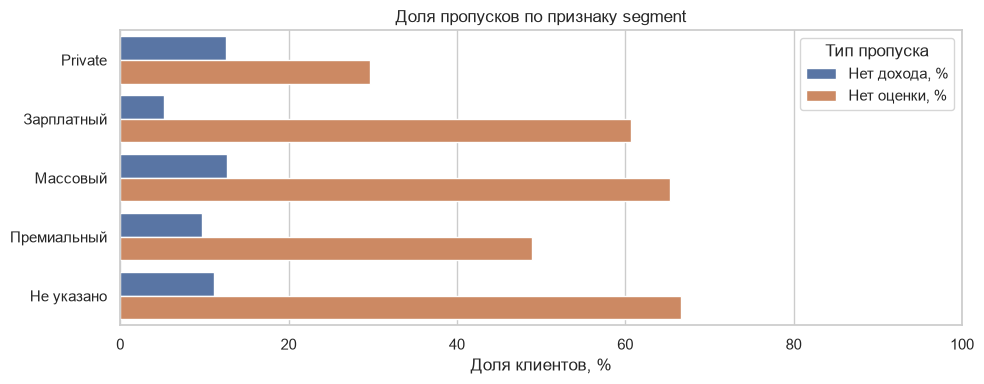

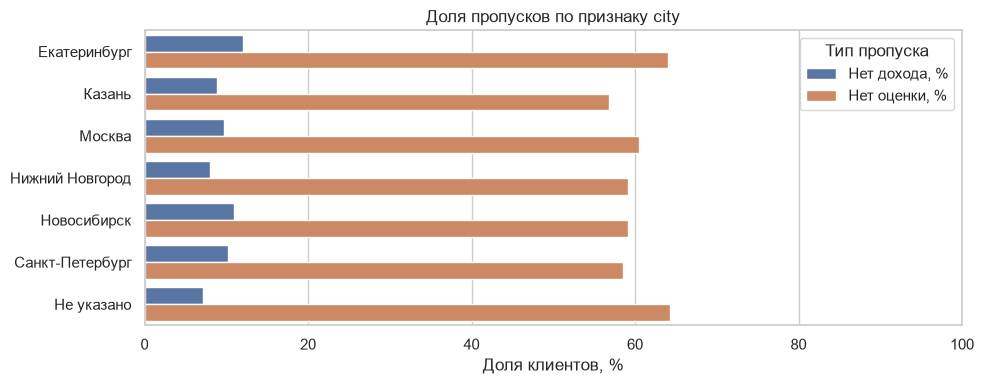

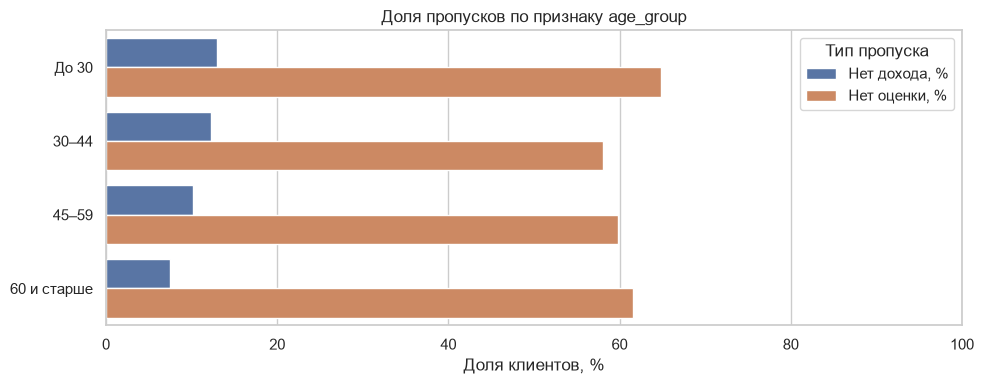

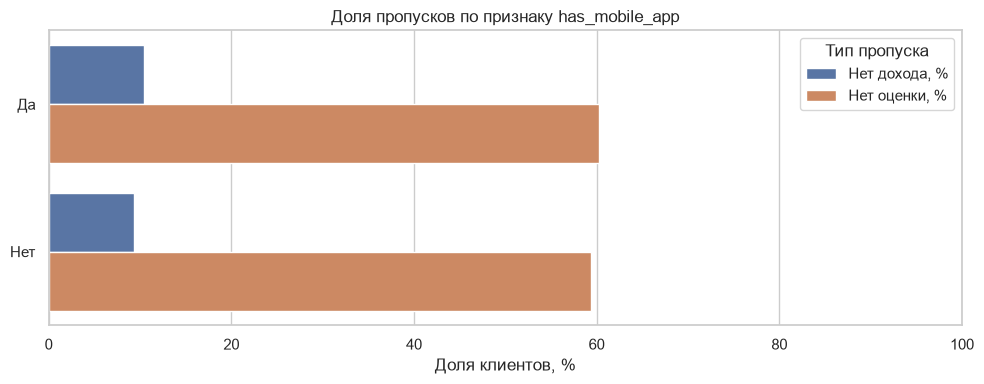

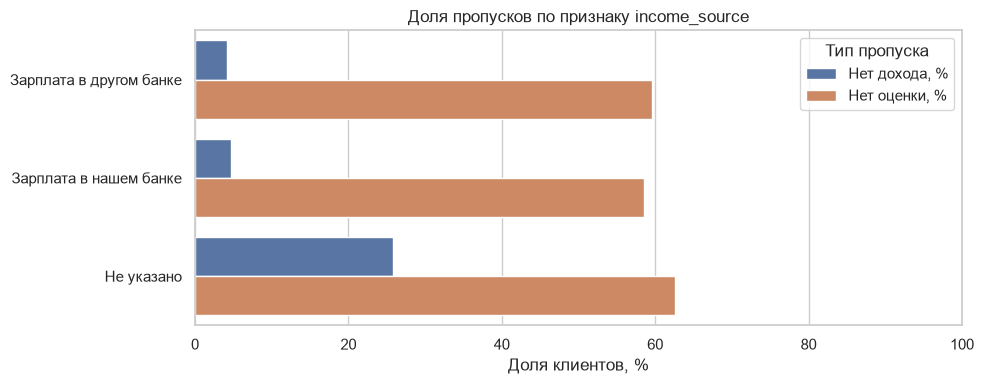

In [32]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

for col in ["segment", "city", "age_group", "has_mobile_app", "income_source"]:
    data = missing_groups[missing_groups["Признак"] == col].copy()
    data["Группа"] = data["Группа"].fillna("Не указано")

    plot_data = data.melt(
        id_vars="Группа",
        value_vars=["Нет дохода, %", "Нет оценки, %"],
        var_name="Тип пропуска",
        value_name="Доля, %"
    )

    plt.figure(figsize=(10, max(4, len(data) * 0.55)))

    sns.barplot(
        data=plot_data,
        y="Группа",
        x="Доля, %",
        hue="Тип пропуска",
        orient="h"
    )

    plt.title(f"Доля пропусков по признаку {col}")
    plt.xlabel("Доля клиентов, %")
    plt.ylabel("")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()

In [33]:
#проверяем, как пропуски доходов и оценок зависят сразу от двух признаков.

income_by_group = missing_context.groupby(["income_source", "segment"], dropna=False).agg(
    Клиентов=("client_id", "size"), Доход_неизвестен=("income_missing", "sum"),
    Доля=("income_missing", "mean"))

income_by_group["Доля"] *= 100

display(income_by_group.rename(columns={"Доля": "Неизвестен доход, %"}).round(2))

score_by_group = missing_context.groupby(["has_mobile_app", "segment"], dropna=False).agg(
    Клиентов=("client_id", "size"), Нет_ответа=("score_missing", "sum"), Доля=("score_missing", "mean"))

score_by_group["Доля"] *= 100

display(score_by_group.rename(columns={"Доля": "Нет ответа, %"}).round(2))
score_frequencies = audit_score.value_counts().sort_index().to_frame("Ответов")
score_frequencies["Доля среди ответивших, %"] = score_frequencies["Ответов"] / audit_score.notna().sum() * 100

display(score_frequencies.round(2))

print("Ответивших:", audit_score.notna().sum(), "; медианная оценка:", audit_score.median())

Клиентов  Доход_неизвестен  \
income_source           segment                                   
Зарплата в другом банке Private            83                 4   
                        Зарплатный        111                 5   
                        Массовый         1032                41   
                        Премиальный       318                15   
                        <NA>                2                 0   
Зарплата в нашем банке  Private            73                 5   
                        Зарплатный       1458                67   
                        Массовый          733                35   
                        Премиальный       386                15   
                        <NA>                6                 1   
<NA>                    Private            66                19   
                        Зарплатный         67                13   
                        Массовый         1106               287   
                        Премиальный       226                60   
                        <NA>                1                 0   

                                     Неизвестен доход, %  
income_source           segment                           
Зарплата в другом банке Private                     4.82  
                        Зарплатный                  4.50  
                        Массовый                    3.97  
                        Премиальный                 4.72  
                        <NA>                        0.00  
Зарплата в нашем банке  Private                     6.85  
                        Зарплатный                  4.60  
                        Массовый                    4.77  
                        Премиальный                 3.89  
                        <NA>                       16.67  
<NA>                    Private                    28.79  
                        Зарплатный                 19.40  
                        Массовый                   25.95  
                        Премиальный                26.55  
                        <NA>                        0.00

Клиентов  Нет_ответа  Нет ответа, %
has_mobile_app segment                                         
Да             Private           134          45          33.58
               Зарплатный       1021         622          60.92
               Массовый         1777        1169          65.79
               Премиальный       574         276          48.08
               <NA>                7           4          57.14
Нет            Private            88          21          23.86
               Зарплатный        615         371          60.33
               Массовый         1094         707          64.63
               Премиальный       356         179          50.28
               <NA>                2           2         100.00

,Ответов,"Доля среди ответивших, %"
satisfaction_score,,
1,288,12.68
2,451,19.85
3,425,18.71
4,427,18.79
5,681,29.97


Ответивших: 2272 ; медианная оценка: 3.0


 Ответили 2272 клиента; медиана 3, оценок 4-5 48,77%, чаще всего ставят 5 (29,97%).

Доли пропусков связаны с известными признаками, гипотеза MCAR сомнительна. MAR и MNAR по этим данным не различить: неизвестно, остается ли связь с самим неуказанным значением после учета других признаков.

(проверяется зависимость пропусков дохода) если источник неизвестен, пропусков 19–29%, иначе около 4–7%

оценка удовлетворенности чаще отсутствует у массового и зарплатного сегментов (60–66%), чем у Private (24–34%)

наличие приложения не показывает устойчивой связи с пропусками оценок

In [34]:
#проверяем, сколько клиентов потеряем при 
# удалении пропусков, и насколько точно можно восстановить неизвестные доходы.


samples = {
    "Все клиенты": pd.Series(True, index=clients_clean.index),
    "Нет пропусков в трёх полях": ~audit_missing.any(axis=1),
    "Доход не пропущен и не -999": ~audit_missing["monthly_income"],
    "Заполнена оценка": ~audit_missing["satisfaction_score"]
}

total = len(clients_clean)
results = []

for name, mask in samples.items():
    data = clients_clean.loc[mask]
    results.append({
        "Выборка": name,
        "Осталось клиентов": len(data),
        "Исключено клиентов": total - len(data),
        "Осталось от базы, %": len(data) / total * 100,
        "Без приложения, чел.": data["has_mobile_app"].eq("Нет").sum(),
        "Неизвестный сегмент, чел.": data["segment"].isna().sum(),
        "Массовый от всей выборки, %": data["segment"].eq("Массовый").sum() / len(data) * 100
    })

display(pd.DataFrame(results).set_index("Выборка").round(2))

income_known = clients_clean.loc[~clients_clean["income_suspicious_low"]].dropna(subset=["monthly_income"])
income_test = income_known.sample(frac=.2,random_state=42)
income_reference = income_known.drop(income_test.index)
estimates = pd.DataFrame({
    "Общая медиана": income_reference["monthly_income"].median(),
    "По сегменту": income_test["segment"].map(income_reference.groupby("segment",dropna=False)["monthly_income"].median()),
    "По сегменту и источнику": income_test.set_index(["segment","income_source"]).index.map(
        income_reference.groupby(["segment","income_source"],dropna=False)["monthly_income"].median())
},index=income_test.index).fillna(income_reference["monthly_income"].median())
error = estimates.sub(income_test["monthly_income"],axis=0).abs()
relative_error = error.div(income_test["monthly_income"],axis=0)
display(pd.DataFrame({"Проверено":len(income_test),"Средняя ошибка, руб.":error.mean(),
                      "Медианная ошибка, %":relative_error.median()*100}))

#мы проверяем пропуски только в трех полях: доход, дата входа, оценка.

,Осталось клиентов,Исключено клиентов,"Осталось от базы, %","Без приложения, чел.","Неизвестный сегмент, чел.","Массовый от всей выборки, %"
Выборка,,,,,,
Все клиенты,5668,0,100.00,2155,9,50.65
Нет пропусков в трёх полях,1244,4424,21.95,0,3,42.68
Доход не пропущен и не -999,5101,567,90.00,1954,8,49.17
Заполнена оценка,2272,3396,40.08,875,3,43.79


,Проверено,"Средняя ошибка, руб.","Медианная ошибка, %"
Общая медиана,984,43584.552846,36.136971
По сегменту,984,29331.707317,26.490066
По сегменту и источнику,984,29429.065041,26.365042


Без пропусков осталось бы 1244 клиента (21,95%) и исчезли бы все клиенты без приложения. Доля массового сегмента меняется с 50,65% до 42,68%; среди ответивших она 43,79%. На 984 скрытых известных доходах групповые медианы дают около 26% медианной относительной ошибки. Доходы, месяцы входа и ответы оставлены неизвестными; сами клиенты сохранены.

income_known содержит 4919 клиентов с известным доходом, без подозрительно низких значений
frac=.2 случайно выбирает 20% этих клиентов

### 5. Распределения и выбросы

In [35]:
income = clients_clean.loc[~clients_clean["income_suspicious_low"],"monthly_income"].dropna()
successful = transactions_analysis.loc[transactions_analysis["status"].eq("успешно")]
rub = successful.loc[successful["currency"].eq("RUB")]
amounts = rub["amount"].dropna()
numeric_samples = {"Доход, RUB":income}
for currency in ["RUB","USD","EUR"]:
    numeric_samples[f"Операция, {currency}"] = successful.loc[successful["currency"].eq(currency),"amount"].dropna()
number_stats = pd.DataFrame({name:values.describe(percentiles=[.25,.5,.75,.95,.99])
                             for name,values in numeric_samples.items()}).T
number_stats["Асимметрия"] = [values.skew() for values in numeric_samples.values()]
display(number_stats[["count", "mean", "50%", "25%", "75%", "95%", "99%", "max", "Асимметрия"]]
    .round(2).set_axis(["N", "Среднее", "Медиана", "Q1", "Q3", "P95", "P99", "Максимум", "Асимметрия"], axis=1))

q1,q3 = number_stats["25%"],number_stats["75%"]
lower = q1-1.5*(q3-q1)
upper = q3+1.5*(q3-q1)
stats_samples = {}
iqr_rows = []
for name,values in numeric_samples.items():
    outside = ~values.between(lower[name],upper[name])
    stats_samples[name] = values.loc[~outside]
    iqr_rows.append([name,lower[name],upper[name],outside.sum(),outside.mean()*100,
                     values[outside].sum()/values.sum()*100,stats_samples[name].mean(),stats_samples[name].median()])
iqr_summary = pd.DataFrame(iqr_rows,columns=["Ряд","Нижняя граница","Верхняя граница","За IQR",
                                           "Доля записей, %","Доля суммы, %","Среднее без IQR","Медиана без IQR"]).set_index("Ряд")
display(iqr_summary.round(2))
income_outliers = income.loc[~income.between(lower["Доход, RUB"],upper["Доход, RUB"])]
amount_outliers = amounts.loc[~amounts.between(lower["Операция, RUB"],upper["Операция, RUB"])]

,N,Среднее,Медиана,Q1,Q3,P95,P99,Максимум,Асимметрия
"Доход, RUB",4919.0,97295.55,74600.0,54500.0,110000.0,239350.0,433206.0,867100.0,3.36
"Операция, RUB",565599.0,1886.41,1087.3,490.41,2266.33,6336.3,12345.9,114061.89,5.13
"Операция, USD",1138.0,18.78,11.08,5.08,22.36,65.04,130.39,234.76,3.48
"Операция, EUR",1169.0,18.79,11.08,5.01,23.56,61.59,118.22,232.14,3.35


,Нижняя граница,Верхняя граница,За IQR,"Доля записей, %","Доля суммы, %",Среднее без IQR,Медиана без IQR
Ряд,,,,,,,
"Доход, RUB",-28750.00,193250.00,380,7.73,24.48,79625.93,71000.00
"Операция, RUB",-2173.47,4930.21,45416,8.03,36.19,1308.72,971.65
"Операция, USD",-20.86,48.29,92,8.08,36.92,12.89,9.88
"Операция, EUR",-22.82,51.38,84,7.19,32.22,13.72,9.99


Доходы и успешные суммы имеют правый хвост. За общим IQR находятся 380 доходов (7,73%, 24,48% суммы) и 45416 RUB-операций (8,03%, 36,19% суммы), также 92 USD- и 84 EUR-операции. Описательные таблицы показывают полный ряд и центральную часть без значений за Q1-1,5*IQR и Q3+1,5*IQR.

In [36]:
context = pd.concat([
    pd.DataFrame({"Индекс": income.index, "Ряд": "Доход", "Группа": clients_clean.loc[income.index,"segment"],
                  "Значение": income, "Общий IQR": income.index.isin(income_outliers.index)}),
    pd.DataFrame({"Индекс": amounts.index, "Ряд": "Успешные RUB-операции", "Группа": rub["category"],
                  "Значение": amounts, "Общий IQR": amounts.index.isin(amount_outliers.index)})
], ignore_index=True)
context["Группа"] = context["Группа"].fillna("Не установлен")
grouped = context.groupby(["Ряд","Группа"])["Значение"]
group_q1 = grouped.transform("quantile", q=.25)
group_q3 = grouped.transform("quantile", q=.75)
context["IQR группы"] = ~context["Значение"].between(
    group_q1-1.5*(group_q3-group_q1), group_q3+1.5*(group_q3-group_q1))
display(context.groupby(["Ряд","Группа"]).agg(
    Наблюдений=("Значение","size"), Общий_IQR=("Общий IQR","sum"), Внутри_группы=("IQR группы","sum")))

print("Сегменты шести наибольших доходов:", clients_clean.loc[income.nlargest(6).index,"segment"].unique().tolist())
display(rub.nlargest(6,"amount")[["amount","category","mcc_code","channel"]])
print("Клиентов с крупными RUB-операциями:", rub.loc[amount_outliers.index,"client_id"].nunique(),
      "; спорных пар категории/MCC:", int(audit_mcc_conflict.loc[amount_outliers.index].sum()))

for name,values in numeric_samples.items():
    field = "clients.monthly_income" if name == "Доход, RUB" else "transactions.amount"
    scope = f"{name}; доход без низких отметок или успешные операции целевой выборки; вне {lower[name]}–{upper[name]}"
    log_change(field,"IQR для описательных расчётов",scope,len(values)-len(stats_samples[name]),
               f"N={len(values)}", "Не включать в описание центральной части; сохранить в CSV",f"В расчёте N={len(stats_samples[name])}; исходные суммы сохранены",
               "Сравнили показатели с полным набором; убираем влияние хвоста только из этих расчётов и графиков")

Наблюдений  Общий_IQR  \
Ряд                   Группа                                       
Доход                 Private                     188        173   
                      Зарплатный                 1499         13   
                      Массовый                   2409          3   
                      Не установлен                 8          0   
                      Премиальный                 815        191   
Успешные RUB-операции АЗС                       51882       5056   
                      Аптеки                    40995        292   
                      Кафе и рестораны          72614       4603   
                      Не установлен              1421        118   
                      Одежда и обувь            57347      23288   
                      Онлайн-сервисы            39690         53   
                      Продукты                 148647       2279   
                      Развлечения и досуг       49038       9629   
                      Связь и интернет          44446         98   
                      Транспорт                 59519          0   

                                           Внутри_группы  
Ряд                   Группа                              
Доход                 Private                          5  
                      Зарплатный                      41  
                      Массовый                        65  
                      Не установлен                    0  
                      Премиальный                     38  
Успешные RUB-операции АЗС                           3149  
                      Аптеки                        2427  
                      Кафе и рестораны              4253  
                      Не установлен                  112  
                      Одежда и обувь                3302  
                      Онлайн-сервисы                2295  
                      Продукты                      8460  
                      Развлечения и досуг           2889  
                      Связь и интернет              2600  
                      Транспорт                     3488

Сегменты шести наибольших доходов: ['Private']


,amount,category,mcc_code,channel
247669,114061.89,Одежда и обувь,5651,Карта
561516,97986.27,Одежда и обувь,5651,Онлайн-банк
261204,88196.27,Одежда и обувь,5651,СБП
148289,87520.42,Одежда и обувь,5651,Карта
609228,87023.5,Одежда и обувь,5651,Карта
335230,79684.12,Одежда и обувь,5651,Карта


Клиентов с крупными RUB-операциями: 5169 ; спорных пар категории/MCC: 118


Общий порог выделяет 173 из 188 доходов Private, а порог внутри сегмента только 5. Шесть наибольших доходов относятся к Private.

Для сравнения сегментов и категорий используются их собственные границы IQR.

### 6. Графики и проверка результата

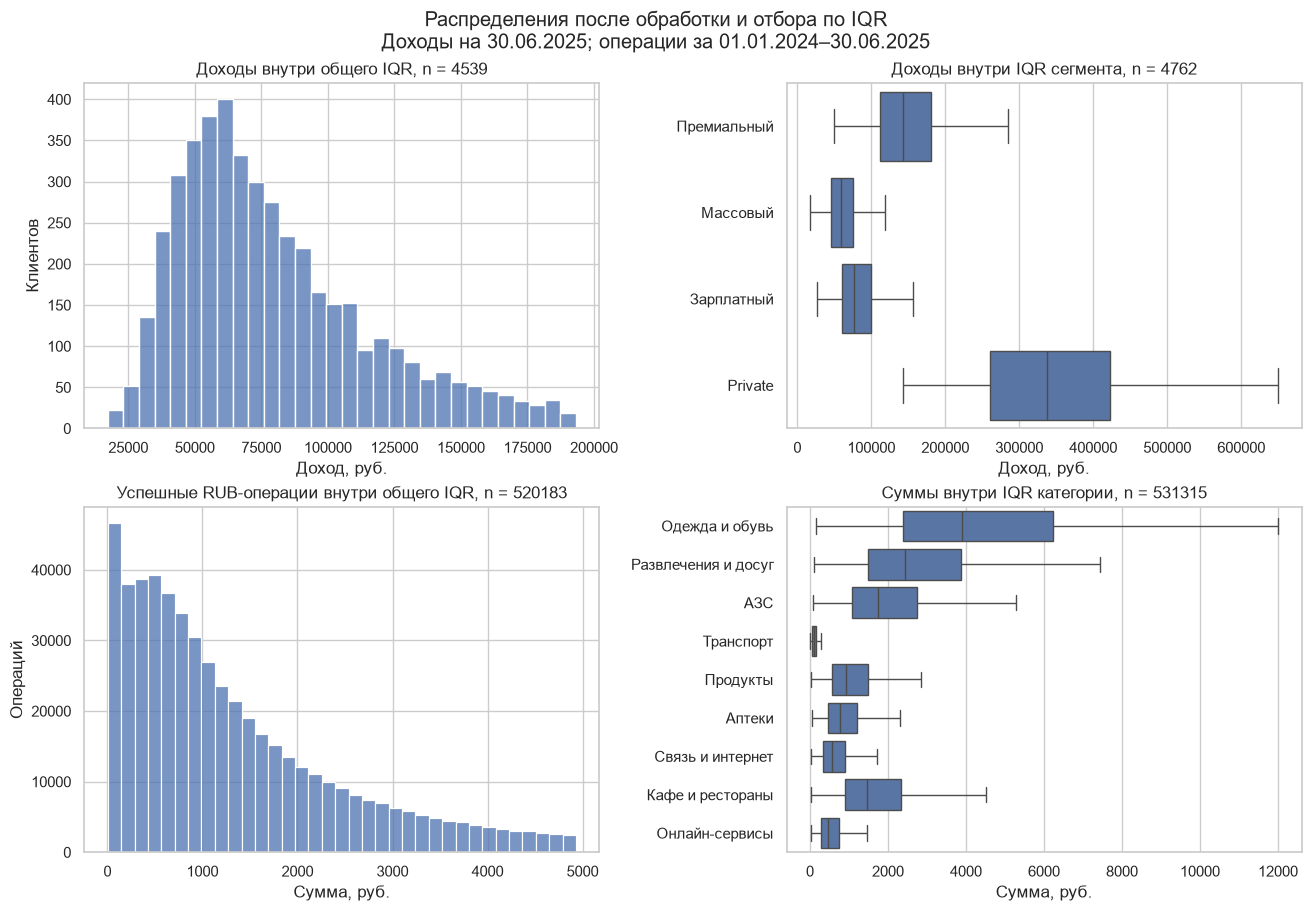

In [37]:

income_plot = stats_samples["Доход, RUB"]
rub_plot = rub.loc[stats_samples["Операция, RUB"].index]

# Для сравнения групп применяем IQR внутри группы, а не общий порог.
income_group_index = context.loc[context["Ряд"].eq("Доход") & ~context["IQR группы"], "Индекс"]
rub_group_index = context.loc[context["Ряд"].eq("Успешные RUB-операции") & ~context["IQR группы"], "Индекс"]
income_groups_plot = clients_clean.loc[income_group_index, ["monthly_income", "segment"]].dropna(subset=["segment"])
category_plot = rub.loc[rub_group_index].dropna(subset=["category"])

log_change("clients.monthly_income", "IQR внутри сегмента для графика", "Известный сегмент и доход без низкой отметки",
           clients_clean.loc[income.index, "segment"].notna().sum() - len(income_groups_plot),
           f"N={clients_clean.loc[income.index, 'segment'].notna().sum()}", "Не включать в этот график; сохранить в CSV",
           f"N={len(income_groups_plot)}", "Общий IQR отсекает почти весь Private; внутри сегмента масштаб сопоставим")
log_change("transactions.amount", "IQR внутри категории для графика", "Успешные RUB-операции выборки с известной категорией",
           rub["category"].notna().sum() - len(category_plot), f"N={rub['category'].notna().sum()}",
           "Не включать в этот график; сохранить в CSV", f"N={len(category_plot)}", "Суммы разных категорий имеют разный масштаб")

fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
sns.histplot(income_plot, bins=30, ax=axes[0, 0])
axes[0, 0].set(title=f"Доходы внутри общего IQR, n = {len(income_plot)}",
               xlabel="Доход, руб.", ylabel="Клиентов")
sns.boxplot(data=income_groups_plot, x="monthly_income", y="segment", showfliers=False, ax=axes[0, 1])
axes[0, 1].set(title=f"Доходы внутри IQR сегмента, n = {len(income_groups_plot)}",
               xlabel="Доход, руб.", ylabel="")
sns.histplot(rub_plot["amount"], bins=35, ax=axes[1, 0])
axes[1, 0].set(title=f"Успешные RUB-операции внутри общего IQR, n = {len(rub_plot)}",
               xlabel="Сумма, руб.", ylabel="Операций")
sns.boxplot(data=category_plot, x="amount", y="category", showfliers=False, ax=axes[1, 1])
axes[1, 1].set(title=f"Суммы внутри IQR категории, n = {len(category_plot)}",
               xlabel="Сумма, руб.", ylabel="")
fig.suptitle("Распределения после обработки и отбора по IQR\n"
             "Доходы на 30.06.2025; операции за 01.01.2024–30.06.2025")
plt.show()

Общие гистограммы содержат 4539 доходов и 520183 RUB-операции. В графиках по известным группам 4762 дохода и 531315 операций; в Private осталось 183 из 188. Пропуски и доходы с низкой отметкой в доходные графики не входят.

In [38]:
assert clients_clean["client_id"].is_unique and transactions_clean["txn_id"].is_unique
assert clients_clean["client_id"].ne("").all() and transactions_clean["txn_id"].ne("").all()
assert set(clients_clean["client_id"]) == set(clients_raw["client_id"])
assert set(transactions_clean["txn_id"]) == set(transactions_raw["txn_id"])


fixed_tx = transactions_raw.columns.drop(["txn_datetime", "amount", "category"])

pd.testing.assert_frame_equal(transactions_clean[fixed_tx], transactions_raw.loc[transactions_clean.index, fixed_tx])
pd.testing.assert_series_equal(transactions_clean["txn_datetime"], txn_calendar.loc[transactions_clean.index])
pd.testing.assert_series_equal(transactions_clean["amount"], numeric_values["amount"].loc[transactions_clean.index])
pd.testing.assert_series_equal(transactions_clean["category"], category_check.loc[transactions_clean.index].mask(uncertain_category))
fixed = ["client_id", "gender", "loyalty_tier", "card_type", "has_mobile_app", "branch_code", "marketing_opt_in"]


pd.testing.assert_frame_equal(clients_clean[fixed], clients_raw.loc[clients_clean.index, fixed])

for col in ["city", "segment"]:
    expected = (city_check if col == "city" else clients_raw[col]).loc[clients_clean.index]
    expected = expected.mask(clients_clean["client_id"].isin(client_disagreements.index[client_disagreements[col]]))
    pd.testing.assert_series_equal(clients_clean[col], expected)
pd.testing.assert_series_equal(clients_clean["income_source"], clients_raw.loc[clients_clean.index, "income_source"].replace("Не указан", pd.NA))
pd.testing.assert_series_equal(clients_clean["monthly_income"], numeric_values["monthly_income"].loc[clients_clean.index].mask(income_code), check_dtype=False)
expected_score = pd.to_numeric(clients_raw.loc[clients_clean.index, "satisfaction_score"].replace("", pd.NA), errors="raise")
pd.testing.assert_series_equal(clients_clean["satisfaction_score"], expected_score, check_dtype=False)
pd.testing.assert_series_equal(clients_clean.loc[income_small,"monthly_income"],income_before.loc[income_small])

assert clients_clean["income_suspicious_low"].eq(income_small).all()
assert not clients_clean.loc[income.index,"income_suspicious_low"].any()
assert len(income) == (clients_clean["monthly_income"].notna() & ~clients_clean["income_suspicious_low"]).sum()
assert clients_clean["monthly_income"].dropna().gt(0).all()
assert clients_clean["monthly_income"].isna().sum() == income_before.isna().sum()+income_code.sum()

for col,fmt in [("birth_date","%Y-%m-%d"),("registration_date","%d.%m.%Y"),
                ("card_open_date","%d.%m.%Y"),("app_last_login","%Y-%m")]:
    expected = parsed_dates[col].loc[clients_clean.index]
    if col == "app_last_login":
        expected = expected.dt.to_period("M").mask(early_login)
    pd.testing.assert_series_equal(clients_clean[col],expected,check_dtype=False)

assert clients_clean["registration_date"].ge(clients_clean["birth_date"]).all()
assert clients_clean["registration_date"].le("2025-06-30").all()
assert clients_clean["card_open_date"].ge(clients_clean["registration_date"]).all()
assert clients_clean["branch_code"].str.fullmatch(r"\d{5}").all()
assert np.isfinite(transactions_clean["amount"]).all()
assert (transactions_clean["amount"].lt(0) == transactions_clean["status"].eq("возврат")).all()

linked = transactions_analysis[["txn_id","client_id"]].merge(clients_clean[["client_id"]],on="client_id",validate="many_to_one")

assert len(linked) == len(transactions_analysis) == int(selected.sum())

for name,values in stats_samples.items():
    expected = numeric_samples[name].loc[numeric_samples[name].between(lower[name],upper[name])]
    pd.testing.assert_series_equal(values,expected)

assert category_plot["category"].notna().all()
assert not category_plot["category_mcc_disagreement"].any()
assert income_groups_plot["segment"].notna().all()
assert not clients_clean.loc[income_groups_plot.index, "income_suspicious_low"].any()
assert income_groups_plot["monthly_income"].notna().all()
assert len(income_groups_plot) == int(context.loc[context["Ряд"].eq("Доход") & context["Группа"].ne("Не установлен"), "IQR группы"].eq(False).sum())
assert len(category_plot) == int(context.loc[context["Ряд"].eq("Успешные RUB-операции") & context["Группа"].ne("Не установлен"), "IQR группы"].eq(False).sum())
assert not clients_clean.loc[income_plot.index,"income_suspicious_low"].any()

print("Ключи, связи, правила замены и незатронутые значения проверены. Клиентов без операций в окне:",
      int((~clients_clean["client_id"].isin(transactions_analysis["client_id"])).sum()))




Ключи, связи, правила замены и незатронутые значения проверены. Клиентов без операций в окне: 10


Проверки ключей, связей и значений прошли. Изменились только предусмотренные поля; малые доходы сохранены и исключены из доходной статистики. Все клиенты, отдельные операции, даты операций и коды сохранены.

In [39]:
log_columns = ["field","issue","scope","n_rows","value_before","action","value_after","rationale"]
cleaning_log = pd.DataFrame(cleaning_records, columns=log_columns)
assert not cleaning_log.duplicated(["field","issue","scope","action"]).any()
processed_dir = output_dir/"data"/"processed"
processed_dir.mkdir(parents=True, exist_ok=True)
saved = []
for filename, data in [("clients_clean.csv",clients_clean), ("transactions_clean.csv",transactions_clean),
                        ("transactions_analysis.csv",transactions_analysis)]:
    path = processed_dir/filename
    data.to_csv(path, index=False, encoding="utf-8-sig")
    check = pd.read_csv(path, dtype="string", keep_default_na=False)
    pd.testing.assert_frame_equal(check, data.astype("string").fillna("").reset_index(drop=True))
    saved.append([filename,len(check),check.shape[1]])
cleaning_log.to_csv(output_dir/"cleaning_log.csv", index=False, encoding="utf-8-sig")
pd.testing.assert_frame_equal(pd.read_csv(output_dir/"cleaning_log.csv",keep_default_na=False), cleaning_log, check_dtype=False)
for name, data in raw_tables.items():
    assert hashlib.sha256((raw_dir/(name+".csv")).read_bytes()).hexdigest() == source_hashes[name+".csv"]
    assert hashlib.sha256(pd.util.hash_pandas_object(data,index=True).values.tobytes()).hexdigest() == raw_fingerprints[name]
display(pd.DataFrame(saved, columns=["Файл","Строк","Столбцов"]))
print("Правил журнала:",len(cleaning_log),"; исходные CSV и raw не изменены.")

,Файл,Строк,Столбцов
0,clients_clean.csv,5668,20
1,transactions_clean.csv,614697,14
2,transactions_analysis.csv,586526,14


Правил журнала: 39 ; исходные CSV и raw не изменены.


Три CSV записаны и перечитаны без различий. В журнале 39 правил Блока II; повторный запуск пересоздает журнал. n_rows относится к своему правилу, эти числа не являются общей потерей строк. SHA-256 и отпечатки raw совпали.

### Результат обработки

| Что обработано | Изменение и проверка |
|---|---|
| Повторы | Убраны 41 копия клиента, 1306 копий операций, 194 менее полные записи; 5668 клиентов и 614697 операций, все ID сохранены |
| Написания | 1609 замен города, 50906 категории; 6 городов и 9 категорий |
| Противоречия | 28 значений города и 18 сегмента заменены на NA; 14 клиентов сохранены |
| Доход | 56 кодов -999 стали NA; 567 пропусков, 5101 число; 182 низких значения с флагом; в основной статистике 4919 |
| Источник зарплаты | 1466 обозначений "Не указан" стали NA |
| Приложение | 21 неверный месяц стал NaT; 2176 неизвестных месяцев, 3492 пригодных |
| Опрос | 3396 NA, 2272 ответа; сохранены исходные оценки, тип Int64 |
| Категория/MCC | 1562 категории стали NA, в выборке 1486; суммы и MCC прежние |
| Крупные значения | Сохранены; отбор по IQR применяется только к показанным статистикам и графикам |
| Выборка | 586526 операций, все валюты и статусы; исключения доступны в полной таблице |

Для дальнейшей работы: clients_clean содержит клиентов, transactions_clean все отдельные операции, transactions_analysis операции клиентов снимка за наш период. Правильные города/сегменты спорных клиентов, единицы малых доходов, 21 месяц входа и спорные пары MCC остаются неизвестны.

## Блок III. Активность клиентов

### 7. Состав базы после обработки


In [40]:
#смотрим распределение клиентов по городу, 
#сегменту, уровню лояльности, типу карты, наличию приложения и согласию на маркетинг.

client_frequencies = []
for col in ["city", "segment", "loyalty_tier", "card_type", "has_mobile_app", "marketing_opt_in"]:
    counts = clients_clean[col].value_counts(dropna=False)
    if col == "loyalty_tier":
        counts = counts.reindex(["Базовый", "Серебро", "Золото", "Платина"], fill_value=0)
    table = counts.rename_axis("Значение").reset_index(name="Клиентов")
    table.insert(0, "Признак", col)
    table["Доля от всех клиентов, %"] = table["Клиентов"] / len(clients_clean) * 100
    client_frequencies.append(table)
with pd.option_context("display.max_rows", 35):
    display(pd.concat(client_frequencies, ignore_index=True).round(2))

,Признак,Значение,Клиентов,"Доля от всех клиентов, %"
0,city,Москва,1628,28.72
1,city,Санкт-Петербург,1002,17.68
2,city,Екатеринбург,893,15.76
3,city,Нижний Новгород,732,12.91
4,city,Казань,704,12.42
5,city,Новосибирск,695,12.26
6,city,<NA>,14,0.25
7,segment,Массовый,2871,50.65
8,segment,Зарплатный,1636,28.86
9,segment,Премиальный,930,16.41


В базе 5668 клиентов: массовый сегмент 50,65%, приложение есть у 61,98%, согласие у 5033 человек. Доли посчитаны по отдельным клиентам, включая неизвестные признаки.

( неизвестные значения не относим к массовому или другому сегменту, но учитываем в общем количестве клиентов при расчете долей.)

### 8. Метрика и клиентские таблицы

Основная активность: успешные Карта + Токен во всех валютах. F24 = N24/12, F25 = N25/6, delta = F25-F24. Относительное изменение F25/F24-1

Отказы и возвраты не считаются покупками; суммы считаются отдельно в RUB. 

Для полного сравнения берем зарегистрированных не позже 01.01.2024.

Дата текущей карты не обязательно дата первой карты. В клиентских месяцах до регистрации строк нет; первый месяц позднего клиента может быть неполным.

In [41]:
months = pd.period_range("2024-01", "2025-06", freq="M")
grid = pd.MultiIndex.from_product([clients_clean["client_id"], months], names=["client_id", "month"]).to_frame(index=False)

registration_month = clients_clean.set_index("client_id")["registration_date"].dt.to_period("M") #проверяет, был ли месяц раньше месяца регистрации
grid_before_registration = grid["month"].lt(grid["client_id"].map(registration_month))

client_month = grid.loc[~grid_before_registration].copy()

success_ops = transactions_analysis.loc[transactions_analysis["status"].eq("успешно")].copy()
success_ops["month"] = success_ops["txn_datetime"].dt.to_period("M")

channel_month = success_ops.groupby(["client_id", "month", "channel"]).size().unstack("channel", fill_value=0)
channel_month = channel_month.rename(columns={"Карта": "plastic_ops", "Токен": "token_ops", "СБП": "sbp_ops", "Онлайн-банк": "online_ops"})
channel_cols = ["plastic_ops", "token_ops", "sbp_ops", "online_ops"]
client_month = client_month.merge(channel_month.reset_index(), on=["client_id", "month"], how="left", validate="one_to_one")
client_month[channel_cols] = client_month[channel_cols].fillna(0).astype("int64")

rub_card_ops = success_ops.loc[success_ops["channel"].isin(["Карта", "Токен"]) & success_ops["currency"].eq("RUB")]
money_month = rub_card_ops.groupby(["client_id", "month"]).agg(card_rub_ops=("txn_id", "size"), card_rub_sum=("amount", "sum"))

client_month = client_month.merge(money_month.reset_index(), on=["client_id", "month"], how="left", validate="one_to_one")#учитываем месяцы с нулем операци
client_month["card_rub_ops"] = client_month["card_rub_ops"].fillna(0).astype("int64")
client_month["card_rub_sum"] = client_month["card_rub_sum"].fillna(0).round(2)
client_month["card_ops"] = client_month["plastic_ops"] + client_month["token_ops"]
client_month["all_success_ops"] = client_month[channel_cols].sum(axis=1)

assert not client_month.duplicated(["client_id", "month"]).any()
assert client_month["all_success_ops"].sum() == len(success_ops)
assert client_month["card_ops"].sum() == success_ops["channel"].isin(["Карта", "Токен"]).sum()
assert np.isclose(client_month["card_rub_sum"].sum(), rub_card_ops["amount"].sum())

log_change("client_month.*", "Месяцы до регистрации", "Число не созданных строк: month < месяц registration_date", grid_before_registration.sum(),
           len(grid), "Не создавать нулевую историю до регистрации", len(client_month), "Клиент ещё не мог пользоваться банком")
log_change("client_month.*", "Помесячные счётчики и сумма RUB", "Число входных успешных операций; группировка client_id × month; нули только после регистрации", len(success_ops),
           f"Операций={len(success_ops)}", "Посчитать каналы и оплаты; добавить месяцы без наблюдений со счётчиками 0", f"Строк={len(client_month)}; столбцов={client_month.shape[1]}",
           "Сохраняем всех клиентов; рублёвые суммы агрегируем до копеек, другие валюты в них не входят")

display(client_month.head(6))

print("Клиент-месяцев:", len(client_month), "; месяцев до регистрации не создано:", grid_before_registration.sum())

,client_id,month,plastic_ops,online_ops,sbp_ops,token_ops,card_rub_ops,card_rub_sum,card_ops,all_success_ops
0,C003407,2024-01,3,0,0,0,3,5500.67,3,3
1,C003407,2024-02,3,2,1,0,3,11018.63,3,6
2,C003407,2024-03,3,1,1,0,3,4589.1,3,5
3,C003407,2024-04,3,1,1,0,3,6961.7,3,5
4,C003407,2024-05,3,1,2,1,4,15076.54,4,7
5,C003407,2024-06,2,0,0,1,3,7171.99,3,3


Клиент-месяцев: 101468 ; месяцев до регистрации не создано: 556


Получено 101468 строк client_month; 556 месяцев до регистрации не создавались. В строке счетчики четырех каналов, их общий итог, Карта + Токен и рублевая сумма таких оплат. Числа операций и суммы совпали с входными данными

In [42]:
annual = client_month.assign(year=client_month["month"].dt.year, active=client_month["card_ops"].gt(0)).groupby(["client_id", "year"]).agg(
    card_ops=("card_ops", "sum"), all_success_ops=("all_success_ops", "sum"), rub_ops=("card_rub_ops", "sum"),
    rub_sum=("card_rub_sum", "sum"), active_months=("active", "sum")).unstack("year", fill_value=0)
#собираем годовые показатели
annual.columns = [f"{field}_{year}" for field, year in annual.columns]

client_metrics = clients_clean.merge(annual.reset_index(), on="client_id", how="left", validate="one_to_one")
comparable = client_metrics["registration_date"].le("2024-01-01")
#выбираем сравнимых клиентов 5556 из 5668

client_metrics["comparable"] = comparable
client_metrics["f24"] = (client_metrics["card_ops_2024"] / 12).where(comparable)
client_metrics["f25"] = (client_metrics["card_ops_2025"] / 6).where(comparable)
#считаем частоту карточных оплат

change_units = 2 * client_metrics["card_ops_2025"] - client_metrics["card_ops_2024"]
client_metrics["delta"] = (change_units / 12).where(comparable)
#считаем изменение активности

client_metrics["relative_change"] = client_metrics["f25"] / client_metrics["f24"].replace(0, np.nan) - 1

h1_counts = client_month.loc[client_month["month"].between("2024-01", "2024-06")].groupby("client_id")["card_ops"].sum()
#дополнительно сравниваем одинаковые полугодия (проблема сезонности)


client_metrics["n24_h1"] = client_metrics["client_id"].map(h1_counts).fillna(0).astype("int64")
client_metrics["f24_h1"] = (client_metrics["n24_h1"] / 6).where(comparable)
client_metrics["delta_h1"] = ((client_metrics["card_ops_2025"] - client_metrics["n24_h1"]) / 6).where(comparable)
client_metrics["other_delta"] = ((client_metrics["all_success_ops_2025"] - client_metrics["card_ops_2025"]) / 6
    - (client_metrics["all_success_ops_2024"] - client_metrics["card_ops_2024"]) / 12).where(comparable)

client_metrics["declined"] = change_units.lt(0).astype("boolean").mask(~comparable)


sharp = change_units.le(-12) & (20 * client_metrics["card_ops_2025"]).le(7 * client_metrics["card_ops_2024"])
# минимум на 1 оплату в месяц меньше и снижение минимум на 30% (усиленное условие sharp decline)


client_metrics["practical_decline"] = sharp.astype("boolean").mask(~comparable)
client_metrics["decline_both_windows"] = (sharp & client_metrics["delta_h1"].lt(0)).astype("boolean").mask(~comparable)
#проверяем снижение в обоих сравнениях (по полугодиям и полный 24/месяц и 25 часть)


birth = client_metrics["birth_date"]
client_metrics["age"] = 2025 - birth.dt.year - (birth.dt.month.gt(6) | (birth.dt.month.eq(6) & birth.dt.day.gt(30))).astype(int)
#считаем возраст на 30 июня 2025


analysis = client_metrics.loc[comparable].copy()
cohort_ids = analysis["client_id"]
#сравнимая выборка


assert analysis["delta"].notna().all() and client_metrics["client_id"].is_unique
assert client_month.loc[client_month["client_id"].isin(cohort_ids)].groupby("client_id").size().eq(18).all()

log_change("client_metrics.*", "Клиентские показатели активности", "Число выходных строк; все клиенты; частоты и изменения только при registration_date <= 2024-01-01", len(client_metrics),
           f"Клиентов={len(clients_clean)}", "Рассчитать годовые счётчики, частоты, изменения и возраст", f"Строк={len(client_metrics)}; сравнимых={len(analysis)}", "Периоды делим на 12 и 6; при нулевой базе относительное изменение неизвестно")
log_change("client_metrics.practical_decline, decline_both_windows", "Рабочие признаки заметного снижения", "Все строки новых признаков; NA вне сравнимой выборки; practical: delta <= -1 и F25/F24 <= 0.7; both: также delta_h1 < 0", len(client_metrics),
           "Нет столбцов", "Добавить признаки без удаления клиентов", f"practical={client_metrics['practical_decline'].sum()}; both={client_metrics['decline_both_windows'].sum()}; NA={(~comparable).sum()}", "Сочетаем абсолютный и относительный пороги; полугодия проверяем отдельно; это рабочее правило, не статистический тест")

display(pd.Series({"Всего клиентов": len(client_metrics), "Сравнимая выборка": len(analysis), "Поздняя регистрация": (~comparable).sum(),
    "С согласием в выборке": analysis["marketing_opt_in"].eq("Да").sum(), "Нулевая база 2024": analysis["f24"].eq(0).sum()}, name="Клиентов").to_frame())

,Клиентов
Всего клиентов,5668
Сравнимая выборка,5556
Поздняя регистрация,112
С согласием в выборке,4928
Нулевая база 2024,358


В client_metrics сохранены все 5668 клиентов. Полностью сравнимы 5556, поздних 112; у 358 нулевая база 2024, относительный процент не рассчитан. Для заметного падения заданы оба рабочих порога: минимум 1 оплата в месяц и 30%.

decline_both_windows дополнительно проверяет, что количество карточных оплат снизилось и при сравнении одинаковых полугодий, то есть января-июня 2024 и января-июня 2025. достаточно любого снижения, даже меньше 30%.


358 не совершили ни одной наблюдаемой карточной оплаты в 2024. процентное изменение для них посчитать нельзя, поскольку пришлось бы делить на ноль.

,N,F24,F25,Снизились,"Доля снизивших, %",Без оплат в 2025
Выборка,,,,,,
Все сравнимые,5556,4.044,3.434,3326,59.863,127
Из них с согласием,4928,4.067,3.439,2961,60.085,108
Из них с оплатами в 2024,5198,4.322,3.619,3326,63.986,83


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,IQR
f24,5556.0,4.044,3.314,0.00,1.750,3.542,5.583,8.000,10.021,15.167,37.250,3.833
f25,5556.0,3.434,3.275,0.00,1.167,2.500,4.667,7.667,9.667,14.908,33.167,3.500
delta,5556.0,-0.610,1.893,-14.75,-1.583,-0.417,0.500,1.417,2.083,3.871,7.583,2.083


,Строк в raw,Отдельных оплат,Копий убрано,Месяцев,Частота raw,Частота после обработки
2024,270270,269599,671,12,4.0537,4.0437
2025,114708,114463,245,6,3.4410,3.4336


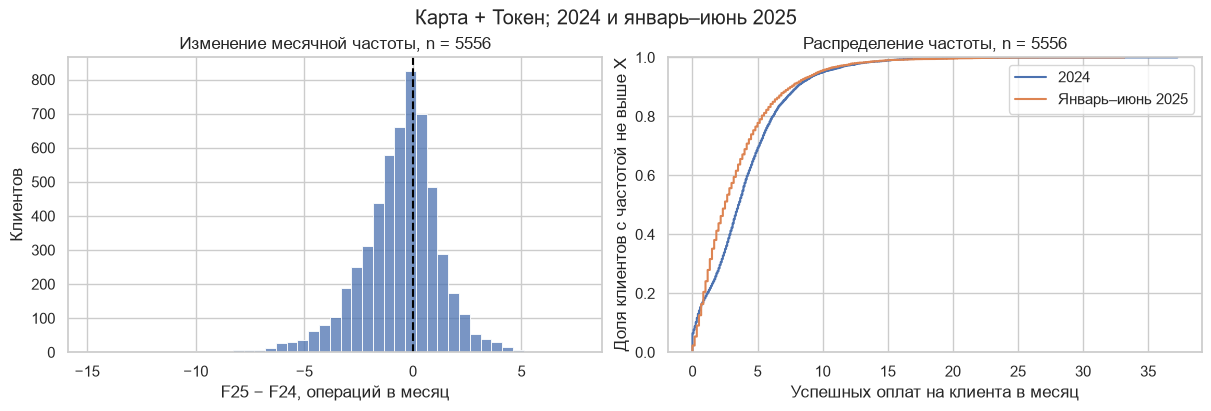

In [43]:
overall_rows = []
for label, part in [("Все сравнимые", analysis), ("Из них с согласием", analysis.loc[analysis["marketing_opt_in"].eq("Да")]),
                    ("Из них с оплатами в 2024", analysis.loc[analysis["f24"].gt(0)])]:
    overall_rows.append([label, len(part), part["f24"].mean(), part["f25"].mean(), part["declined"].sum(),
                         part["declined"].sum() / len(part) * 100, part["f25"].eq(0).sum()])
display(pd.DataFrame(overall_rows, columns=["Выборка", "N", "F24", "F25", "Снизились", "Доля снизивших, %", "Без оплат в 2025"]).set_index("Выборка").round(3))
activity_stats = analysis[["f24", "f25", "delta"]].describe(percentiles=[.25, .5, .75, .9, .95, .99]).T
activity_stats["IQR"] = activity_stats["75%"] - activity_stats["25%"]
display(activity_stats.round(3))

# Условия отбора одинаковы: меняется только устранение технических копий.
raw_card_mask = transactions_raw["client_id"].isin(cohort_ids) & inside_period & transactions_raw["status"].eq("успешно") & transactions_raw["channel"].isin(["Карта", "Токен"])
raw_card_counts = transactions_raw.loc[raw_card_mask].groupby(txn_calendar.loc[raw_card_mask].dt.year).size()
clean_counts = pd.Series({2024: analysis["card_ops_2024"].sum(), 2025: analysis["card_ops_2025"].sum()})
raw_comparison = pd.DataFrame({"Строк в raw": raw_card_counts, "Отдельных оплат": clean_counts})
raw_comparison["Копий убрано"] = raw_comparison["Строк в raw"] - raw_comparison["Отдельных оплат"]
raw_comparison["Месяцев"] = [12, 6]
raw_comparison["Частота raw"] = raw_comparison["Строк в raw"] / raw_comparison["Месяцев"] / len(analysis)
raw_comparison["Частота после обработки"] = raw_comparison["Отдельных оплат"] / raw_comparison["Месяцев"] / len(analysis)
display(raw_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
sns.histplot(analysis["delta"], bins=45, ax=axes[0])
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set(title=f"Изменение месячной частоты, n = {len(analysis)}", xlabel="F25 − F24, операций в месяц", ylabel="Клиентов")
sns.ecdfplot(analysis["f24"], label="2024", ax=axes[1])
sns.ecdfplot(analysis["f25"], label="Январь–июнь 2025", ax=axes[1])
axes[1].set(title=f"Распределение частоты, n = {len(analysis)}", xlabel="Успешных оплат на клиента в месяц", ylabel="Доля клиентов с частотой не выше X")
axes[1].legend()
fig.suptitle("Карта + Токен; 2024 и январь–июнь 2025")
plt.show()



Средняя частота(среднее количество карточных оплат на одного клиента в месяц) 4,044 → 3,434,

личное изменение в среднем -0,610, медиана -0,417;

средняя половина изменений от -1,583 до +0,500. iqr

Снизились 3326 из 5556 (59,86%); (кол-во клиентов)

среди клиентов с согласием снизились 2961 из 4928 (60,09%)

Без оплат в 2025 остались 127, из них 83 платили в 2024.

ECDF показывает долю клиентов, совершающих не больше X оплат в месяц. Чем выше линия при одинаковом X, тем больше доля клиентов с частотой не выше этого значения.

В области низких и средних частот оранжевая линия за 2025 год в основном выше синей. Например, доля клиентов со средней частотой не больше 2 оплат в месяц выросла с 28,51% до 43,74%. При этом линии пересекаются: клиентов совсем без наблюдаемых карточных оплат стало меньше, с 358 до 127.


### 9. Время, каналы и суммы

,N,"База, оплат/мес.","2025, оплат/мес.","Изменение, оплат/мес.","Изменение, %"
Сравнение,,,,,
2024 год → H1 2025,5556,4.044,3.434,-0.610,-15.086
H1 2024 → H1 2025,5556,3.737,3.434,-0.303,-8.108


,"Доля активных клиент-месяцев, %",Оплат на активный клиент-месяц
2024,81.139,4.984
2025,79.734,4.306


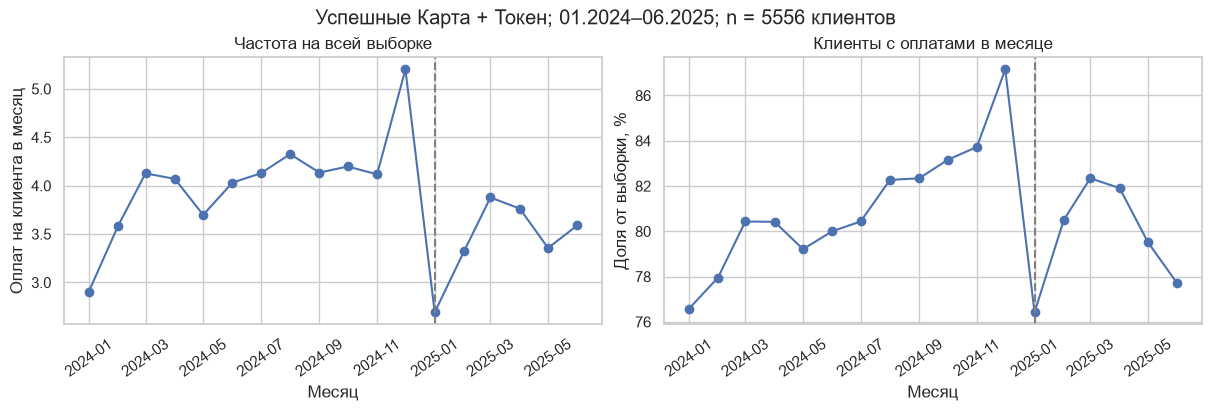

In [44]:
#почему снизилась карточная активность и не связано ли это с сезонностью.

cohort_month = client_month.loc[client_month["client_id"].isin(cohort_ids)].copy()
cohort_month["active"] = cohort_month["card_ops"].gt(0)

monthly = cohort_month.groupby("month").agg(
    card_ops=("card_ops", "sum"), active_clients=("active", "sum"))
monthly["frequency"] = monthly["card_ops"] / len(analysis)
monthly["active_share"] = monthly["active_clients"] / len(analysis) * 100

calendar_rows = []

for label, base in [("2024 год → H1 2025", analysis["f24"]), ("H1 2024 → H1 2025", analysis["f24_h1"])]:
    calendar_rows.append([label, len(analysis), base.mean(), analysis["f25"].mean(),
                          (analysis["f25"] - base).mean(), (analysis["f25"].mean() / base.mean() - 1) * 100])
calendar_check = pd.DataFrame(calendar_rows, columns=["Сравнение", "N", "База, оплат/мес.", "2025, оплат/мес.", "Изменение, оплат/мес.", "Изменение, %"]).set_index("Сравнение")

display(calendar_check.round(3))
active_decomposition = pd.DataFrame(index=[2024, 2025])
active_decomposition["Доля активных клиент-месяцев, %"] = [analysis["active_months_2024"].sum() / (12 * len(analysis)) * 100,
                                                           analysis["active_months_2025"].sum() / (6 * len(analysis)) * 100]
active_decomposition["Оплат на активный клиент-месяц"] = [analysis["card_ops_2024"].sum() / analysis["active_months_2024"].sum(),
                                                          analysis["card_ops_2025"].sum() / analysis["active_months_2025"].sum()]
display(active_decomposition.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, col, title, unit in [(axes[0], "frequency", "Частота на всей выборке", "Оплат на клиента в месяц"),
                             (axes[1], "active_share", "Клиенты с оплатами в месяце", "Доля от выборки, %")]:
    ax.plot(monthly.index.to_timestamp(), monthly[col], marker="o")
    ax.axvline(pd.Timestamp("2025-01-01"), color="gray", linestyle="--")
    ax.set(title=title, xlabel="Месяц", ylabel=unit)
    ax.tick_params(axis="x", rotation=35)

fig.suptitle(f"Успешные Карта + Токен; 01.2024–06.2025; n = {len(analysis)} клиентов")
plt.show()

при сравнении всего 2024 года с первым полугодием 2025 количество карточных оплат на клиента в месяц снизилось на 15,09%. если сравнивать одинаковые полугодия, снижение составляет 8,11%.

доля месяцев, в которых клиенты совершали хотя бы одну оплату, уменьшилась с 81,14% до 79,73%. при этом среднее количество оплат в такие месяцы снизилось с 4,984 до 4,306.

получается, клиенты стали немного реже пользоваться картой, но основное снижение связано с тем, что в активные месяцы они совершают меньше оплат. при этом данных за полтора года недостаточно, чтобы уверенно судить о сезонности


year,2024,2025,Изменение,"Изменение, %"
channel,,,,
Карта,17639.00,12855.67,-4783.33,-27.12
Онлайн-банк,4877.25,3979.67,-897.58,-18.40
СБП,6138.33,4408.67,-1729.67,-28.18
Токен,4827.58,6221.50,1393.92,28.87


year,2024,2025,Изменение,"Изменение, %"
category,,,,
Развлечения и досуг,2069.50,1383.67,-685.83,-33.14
Аптеки,1626.83,1377.50,-249.33,-15.33
Связь и интернет,1764.25,1496.83,-267.42,-15.16
Продукты,5894.75,5033.67,-861.08,-14.61
Транспорт,2361.58,2018.50,-343.08,-14.53
Онлайн-сервисы,1565.67,1358.33,-207.33,-13.24
АЗС,2032.08,1795.67,-236.42,-11.63
Одежда и обувь,2249.25,2006.50,-242.75,-10.79
Кафе и рестораны,2846.83,2556.00,-290.83,-10.22


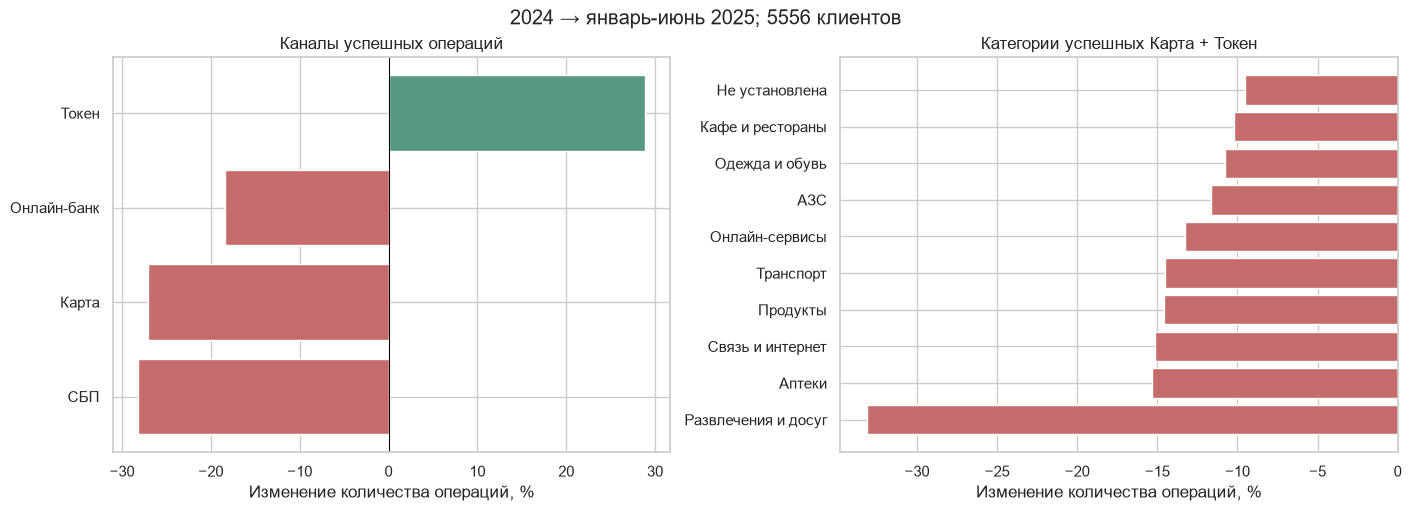

In [45]:

# считаем успешные операции по каналам и категориям
cohort_success = success_ops.loc[
    success_ops["client_id"].isin(cohort_ids)
].copy()

cohort_success["year"] = cohort_success["month"].dt.year

by_channel = cohort_success.groupby(
    ["channel", "year"]
).size().unstack(fill_value=0)

cohort_card = cohort_success.loc[
    cohort_success["channel"].isin(["Карта", "Токен"])
].copy()

by_category = cohort_card.groupby(
    ["category", "year"], dropna=False
).size().unstack(fill_value=0)

# приводим оба периода к среднему числу операций в месяц
for table in [by_channel, by_category]:
    table[2024] = table[2024] / 12
    table[2025] = table[2025] / 6

    table["Изменение"] = table[2025] - table[2024]

    table["Изменение, %"] = (
        (table[2025] / table[2024].replace(0, np.nan) - 1) * 100
    )

display(by_channel.round(2))
display(by_category.sort_values("Изменение, %").round(2))

# проверяем что абсолютные изменения сходятся
assert np.isclose(
    by_channel.loc[["Карта", "Токен"], "Изменение"].sum(),
    analysis["delta"].sum()
)

assert np.isclose(
    by_category["Изменение"].sum(),
    analysis["delta"].sum()
)

# строим графики процентного изменения
fig, axes = plt.subplots(
    1, 2, figsize=(14, 5), layout="constrained"
)

for ax, table, title in [
    (axes[0], by_channel, "Каналы успешных операций"),
    (axes[1], by_category, "Категории успешных Карта + Токен")
]:
    values = table["Изменение, %"].sort_values()

    colors = np.where(values.lt(0), "#c56b6b", "#579884")

    ax.barh(
        values.index.astype("string").fillna("Не установлена"),
        values,
        color=colors
    )

    ax.axvline(0, color="black", linewidth=0.7)
    ax.set(
        title=title,
        xlabel="Изменение количества операций, %"
    )

fig.suptitle(
    f"2024 → январь-июнь 2025; {len(analysis)} клиентов"
)

plt.show()


количество оплат пластиковой картой снизилось примерно на 4783 операции в месяц, при этом через токен стали платить чаще, прирост составил 1394 операции. количество операций через СБП и онлайн-банк тоже сократилось.

снижение наблюдается во всех категориях карточных оплат. больше всего по количеству операций сократились покупки продуктов (-861 в месяц) и расходы на развлечения (-686 в месяц).

операции с неизвестной категорией посчитаны отдельно. общая сумма изменений по категориям совпадает с итоговым снижением карточной активности.

In [46]:
money_rows = []
for year, n_months in [(2024, 12), (2025, 6)]:
    n_ops = analysis[f"rub_ops_{year}"]
    amounts = analysis[f"rub_sum_{year}"]
    client_ticket = amounts / n_ops.replace(0, np.nan)
    money_rows.append([year, n_ops.gt(0).sum(), n_ops.sum() / n_months, amounts.sum() / n_months,
                       amounts.sum() / n_ops.sum(), client_ticket.median()])
money_check = pd.DataFrame(money_rows, columns=["Год", "Клиентов с RUB-оплатами", "RUB-оплат в месяц", "Оборот RUB в месяц",
                                               "Средний чек RUB", "Медиана клиентских средних чеков RUB"]).set_index("Год")
display(money_check.round(2))

currency_check = cohort_card.groupby(["currency", "year"]).agg(
    Операций=("txn_id", "size"), Клиентов=("client_id", "nunique"), Сумма=("amount", "sum"))
years = currency_check.index.get_level_values("year")
period_months = years.map({2024: 12, 2025: 6})
currency_check["Доля оплат за год, %"] = currency_check["Операций"] / years.map(cohort_card.groupby("year").size()) * 100
currency_check["Оплат в месяц"] = currency_check["Операций"] / period_months
currency_check["Сумма в месяц, в валюте строки"] = currency_check["Сумма"] / period_months
display(currency_check.loc[["USD", "EUR"]].drop(columns="Сумма").round(3))

# Состав клиентов одинаковый: меняем только набор валют операций.
rub_declined = (2 * analysis["rub_ops_2025"] - analysis["rub_ops_2024"]).lt(0)
currency_effect = pd.DataFrame({
    "F24": [analysis["f24"].mean(), (analysis["rub_ops_2024"] / 12).mean()],
    "F25": [analysis["f25"].mean(), (analysis["rub_ops_2025"] / 6).mean()],
    "Снизились, клиентов": [analysis["declined"].sum(), rub_declined.sum()]}, index=["Все валюты", "Только RUB"])
currency_effect["Изменение частоты, %"] = (currency_effect["F25"] / currency_effect["F24"] - 1) * 100
display(currency_effect.round(4))
foreign = cohort_card["currency"].ne("RUB")
print(f"Валютных оплат: {foreign.sum()} из {len(cohort_card)} ({foreign.mean() * 100:.3f}%); клиентов с ними: {cohort_card.loc[foreign, 'client_id'].nunique()}")
print("Признак снижения при отборе только RUB меняется у клиентов:", analysis["declined"].ne(rub_declined).sum())

,Клиентов с RUB-оплатами,RUB-оплат в месяц,Оборот RUB в месяц,Средний чек RUB,Медиана клиентских средних чеков RUB
Год,,,,,
2024,5198,22375.25,42993200.78,1921.46,1705.36
2025,5429,18997.00,34258106.51,1803.34,1556.16


Операций  Клиентов  Доля оплат за год, %  Оплат в месяц  \
currency year                                                            
USD      2024       539       499                 0.200         44.917   
         2025       238       226                 0.208         39.667   
EUR      2024       557       525                 0.207         46.417   
         2025       243       233                 0.212         40.500   

               Сумма в месяц, в валюте строки  
currency year                                  
USD      2024                         888.594  
         2025                          714.37  
EUR      2024                         874.307  
         2025                         677.562

,F24,F25,"Снизились, клиентов","Изменение частоты, %"
Все валюты,4.0437,3.4336,3326,-15.0865
Только RUB,4.0272,3.4192,3318,-15.0982


Валютных оплат: 1577 из 384062 (0.411%); клиентов с ними: 1277
Признак снижения при отборе только RUB меняется у клиентов: 38


Рублевый оборот 42,99 → 34,26 млн в месяц;

средний чек 1921 → 1803

, медиана клиентских средних чеков 1705 → 1556 рублей

. В общем среднем чеке вес имеет каждая оплата, в медиане клиентских средних чеков каждый плативший клиент имеет одинаковый вес. 

USD и EUR дают 1577 из 384062 оплат (0,411%), встречаются у 1277 клиентов;

их частота и сумма в месяц тоже снизились.

По всем валютам падение 15,0865%, только по RUB 15,0982%; 

признак любого снижения меняется у 38 клиентов. 

Основная частота учитывает все валюты.

In [47]:
#проверяем две возможные причины снижения карточных оплат. 
#клиенты могли перейти на другие способы оплаты 
# или столкнуться с отказами при оплате.

declining = analysis.loc[analysis["declined"]].copy()
switch_check = pd.Series({
    "Карта + Токен снизились": len(declining),
    "При этом СБП + онлайн-банк выросли": declining["other_delta"].gt(0).sum(),
    "Общая частота всех успешных не снизилась": (2 * declining["all_success_ops_2025"] - declining["all_success_ops_2024"]).ge(0).sum()
}, name="Клиентов").to_frame()
switch_check["Доля от снизивших, %"] = switch_check["Клиентов"] / len(declining) * 100
display(switch_check.round(2))
card_attempts = transactions_analysis.loc[transactions_analysis["client_id"].isin(cohort_ids)
    & transactions_analysis["channel"].isin(["Карта", "Токен"]) & transactions_analysis["status"].isin(["успешно", "отклонено"])].copy()
status_check = pd.crosstab(card_attempts["txn_datetime"].dt.year, card_attempts["status"])
status_check["Отказов, %"] = status_check["отклонено"] / status_check[["успешно", "отклонено"]].sum(axis=1) * 100
display(status_check.round(3))

,Клиентов,"Доля от снизивших, %"
Карта + Токен снизились,3326,100.00
При этом СБП + онлайн-банк выросли,529,15.90
Общая частота всех успешных не снизилась,160,4.81


status,отклонено,успешно,"Отказов, %"
txn_datetime,,,
2024,5529,269599,2.010
2025,2283,114463,1.956


3326 клиентов (100%) стали реже платить картой или токеном.

529 клиентов (15,9%) из них стали чаще пользоваться СБП или онлайн-банком. возможно, часть карточных оплат перешла в другие каналы.

160 клиентов (4,81%) полностью компенсировали снижение карточных оплат другими операциями. у них общее количество успешных операций не уменьшилось, хотя карточных стало меньше.

важно: 160 клиентов входят в число 529, это не отдельная группа.

снижение карточной активности нельзя объяснить ростом отказов, поскольку их доля практически не изменилась. часть клиентов стала чаще использовать СБП и онлайн-банк, но у большинства снижение карточных оплат этим не компенсировалось.


### 10. Группы и статистические проверки

выясняем, у каких групп клиентов карточная активность снизилась сильнее.
сравниваем клиентов по сегменту, возрасту, доходу, городу, типу карты, уровню лояльности и наличию приложения.

,Признак,Группа,N,Медиана F24,Медиана F25,Медиана изменения,"Снизились, %",IQR delta
0,segment,Private,214,3.917,3.333,-0.250,53.738,2.000
1,segment,Зарплатный,1600,4.083,3.583,0.000,49.875,1.917
2,segment,Массовый,2834,3.167,1.833,-0.750,68.666,2.083
3,segment,Премиальный,899,4.083,3.500,-0.083,51.502,2.083
4,segment,<NA>,9,2.583,1.500,0.000,44.444,2.833
5,has_mobile_app,Да,3438,3.667,2.833,-0.250,56.108,1.917
6,has_mobile_app,Нет,2118,3.333,2.000,-0.667,65.958,2.083
7,card_type,Дебетовая,3902,3.500,2.333,-0.417,61.02,2.000
8,card_type,Кредитная,1178,3.667,2.667,-0.333,58.149,2.083
9,card_type,Премиальная,476,4.250,3.250,-0.250,54.622,1.917


N    F24    F25  Среднее изменение  \
segment     has_mobile_app                                          
Private     Да               128  4.042  3.333             -0.384   
            Нет               86  3.292  2.917             -0.431   
Зарплатный  Да               994  4.167  3.833             -0.115   
            Нет              606  3.917  3.333             -0.350   
Массовый    Да              1752  3.250  2.167             -0.756   
            Нет             1082  3.083  1.500             -1.338   
Премиальный Да               557  4.750  4.000             -0.201   
            Нет              342  3.500  2.667             -0.287   
<NA>        Да                 7  2.417  1.500              0.607   
            Нет                2  4.875  4.833             -0.042   

                            Медиана изменения  Снизились, %  IQR delta  
segment     has_mobile_app                                              
Private     Да                         -0.250        54.688      2.021  
            Нет                        -0.208        52.326      1.979  
Зарплатный  Да                          0.000        47.887      1.833  
            Нет                        -0.167        53.135      1.896  
Массовый    Да                         -0.500          62.9      2.000  
            Нет                        -1.167        78.004      2.167  
Премиальный Да                          0.000         49.91      2.083  
            Нет                        -0.167        54.094      2.042  
<NA>        Да                          0.000        42.857      2.042  
            Нет                        -0.042          50.0      1.958

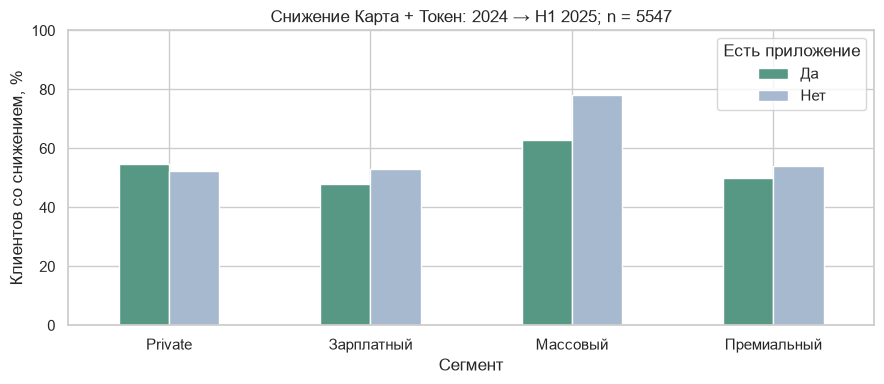

In [48]:
analysis["age_group"] = pd.cut(analysis["age"], [0, 30, 45, 60, np.inf], labels=["До 30 включительно", "31–45", "46–60", "Старше 60"])

income_for_stats = analysis["monthly_income"].mask(analysis["income_suspicious_low"])

analysis["income_group"] = pd.cut(income_for_stats, [0, 50000, 100000, 200000, np.inf],
    labels=["До 50 тыс.", "50–100 тыс.", "100–200 тыс.", "Больше 200 тыс."])
group_rows = []

for col in ["segment", "has_mobile_app", "card_type", "loyalty_tier", "city", "age_group", "income_group"]:
    groups = analysis.groupby(col, observed=True, dropna=False)
    table = groups.agg(N=("client_id", "size"), F24=("f24", "median"), F25=("f25", "median"),
                       delta=("delta", "median"), declined=("declined", "mean"))
    table["IQR delta"] = groups["delta"].quantile(.75) - groups["delta"].quantile(.25)
    table["declined"] *= 100
    assert table["N"].sum() == len(analysis)
    table = table.reset_index().rename(columns={col: "Группа", "F24": "Медиана F24", "F25": "Медиана F25",
        "delta": "Медиана изменения", "declined": "Снизились, %"})
    table.insert(0, "Признак", col)
    group_rows.append(table)

with pd.option_context("display.max_rows", 45):
    display(pd.concat(group_rows, ignore_index=True).round(3))


app_groups = analysis.groupby(["segment", "has_mobile_app"], observed=True, dropna=False)
app_strata = app_groups.agg(N=("client_id", "size"), F24=("f24", "median"), F25=("f25", "median"),
    mean_delta=("delta", "mean"), median_delta=("delta", "median"), declined=("declined", "mean"))
app_strata["IQR delta"] = app_groups["delta"].quantile(.75) - app_groups["delta"].quantile(.25)
app_strata["declined"] *= 100


display(app_strata.rename(columns={"declined": "Снизились, %", "mean_delta": "Среднее изменение", "median_delta": "Медиана изменения"}).round(3))


plot_strata = app_strata.loc[app_strata.index.get_level_values("segment").notna(), "declined"].unstack()
ax = plot_strata.plot.bar(figsize=(9, 4), rot=0, color=["#579884", "#a6b9ce"])
ax.set(title=f"Снижение Карта + Токен: 2024 → H1 2025; n = {int(app_strata.loc[app_strata.index.get_level_values('segment').notna(), 'N'].sum())}",
       xlabel="Сегмент", ylabel="Клиентов со снижением, %", ylim=(0, 100))
ax.legend(title="Есть приложение")
plt.tight_layout()

plt.show()

1. сильнее всего карточная активность снизилась в массовом сегменте. 68,67% клиентов стали платить картой реже, медианное снижение составило 0,75 оплаты в месяц. для сравнения, в зарплатном сегменте снижение наблюдается у 49,88%, в премиальном у 51,50%, в Private у 53,74%.

2. клиенты без мобильного приложения чаще снижают активность, чем клиенты с приложением, 65,96% против 56,11%. особенно заметна разница в массовом сегменте, где без приложения активность снизилась у 78% клиентов, а с приложением у 62,9%. среднее снижение составило 1,34 и 0,76 оплаты в месяц соответственно.

3. снижение чаще встречается среди клиентов старше 60 лет (65,45%) и с доходом до 50 тыс. рублей (64,84%). среди клиентов с доходом выше 200 тыс. рублей активность снизилась у 52,15%. это показывает, что возраст и уровень дохода могут быть связаны с изменением платежного поведения.

4. среди городов больше всего выделяется Екатеринбург, где активность снизилась у 67,16% клиентов. по уровню лояльности сильнее снижение у клиентов с базовым статусом (63,84%), тогда как среди клиентов с золотым статусом доля составляет 51,69%.

в целом наиболее заметное снижение наблюдается среди массовых клиентов без мобильного приложения. также выделяются пожилые клиенты, клиенты с низкими доходами и базовым уровнем лояльности. эти группы стоит рассмотреть для дальнейшего анализа. 

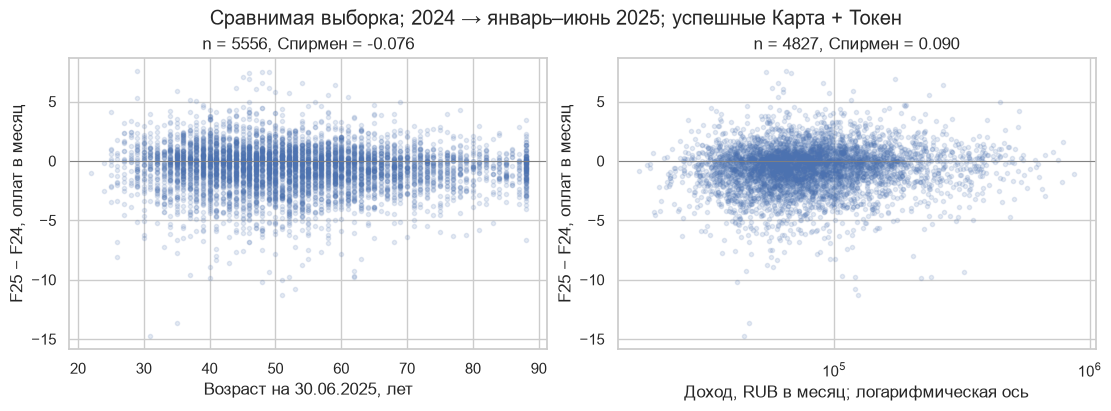

,Признак,Полных пар,Спирмен
0,age,5556,-0.076
1,monthly_income,4827,0.090


In [49]:
correlation_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, col, title in [(axes[0], "age", "Возраст на 30.06.2025, лет"),
                        (axes[1], "monthly_income", "Доход, RUB в месяц; логарифмическая ось")]:
    pairs = analysis[[col, "delta"]].copy()
    if col == "monthly_income":
        pairs[col] = income_for_stats
    pairs = pairs.dropna()
    rho = pairs.rank(method="average").corr().iloc[0, 1]
    correlation_rows.append([col, len(pairs), rho])
    ax.scatter(pairs[col], pairs["delta"], s=9, alpha=.15)
    ax.axhline(0, color="gray", linewidth=.7)
    ax.set(title=f"n = {len(pairs)}, Спирмен = {rho:.3f}", xlabel=title, ylabel="F25 − F24, оплат в месяц")
    if col == "monthly_income":
        ax.set_xscale("log")
fig.suptitle("Сравнимая выборка; 2024 → январь–июнь 2025; успешные Карта + Токен")
plt.show()
display(pd.DataFrame(correlation_rows, columns=["Признак", "Полных пар", "Спирмен"]).round(3))

корреляция спирмена показала очень слабую связь изменения карточной активности с возрастом (-0,076) и доходом (0,090). у старших клиентов наблюдается небольшая тенденция к более сильному снижению, а у клиентов с высоким доходом к меньшему. однако обе зависимости близки к нулю, поэтому возраст и доход по отдельности слабо объясняют изменение активности.

Ранги присвоены после удаления неполных пар. Доходы с низкой отметкой исключены из этого расчета;

In [50]:
from math import comb, erfc, sqrt

# Считаем направление по целым числам, чтобы точный ноль не стал ошибкой округления.
paired_units = 2 * analysis["card_ops_2025"] - analysis["card_ops_2024"]
n_down, n_up, n_same = int(paired_units.lt(0).sum()), int(paired_units.gt(0).sum()), int(paired_units.eq(0).sum())
n_changed = n_down + n_up
p_sign = min(1., 2 * sum(comb(n_changed, k) for k in range(min(n_down, n_up) + 1)) / 2 ** n_changed)

rng = np.random.default_rng(42)
changes = analysis["delta"].to_numpy()
bootstrap_means = np.empty(2000)
for b in range(2000):
    bootstrap_means[b] = rng.choice(changes, size=len(changes), replace=True).mean()
mean_ci = np.quantile(bootstrap_means, [.025, .975])
print(f"Снижение: {n_down}; рост: {n_up}; без изменения: {n_same}")
print(f"Среднее изменение: {changes.mean():.3f}; бутстреп 95%: [{mean_ci[0]:.3f}; {mean_ci[1]:.3f}]")

Снижение: 3326; рост: 2058; без изменения: 172
Среднее изменение: -0.610; бутстреп 95%: [-0.660; -0.560]


Частота снизилась у 3326 клиентов, выросла у 2058, не изменилась у 172. Критерий знаков проверяет направления среди 5384 ненулевых изменений, величину падения не оценивает. Среднее -0,610, бутстреп-интервал 95% от -0,660 до -0,560; 2000 выборок по клиентам

In [51]:
app_counts = pd.crosstab(analysis["has_mobile_app"], analysis["declined"]).reindex(index=["Да", "Нет"], columns=[False, True])
observed = app_counts.to_numpy(dtype=float)
expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / observed.sum()
assert observed.shape == (2, 2) and expected.min() >= 5
chi2 = ((observed - expected) ** 2 / expected).sum()
cramer_v = sqrt(chi2 / observed.sum())

p_chi2 = erfc(sqrt(chi2 / 2))

app_yes = analysis["has_mobile_app"].eq("Да")
n_yes = int(app_yes.sum())
observed_difference = analysis.loc[app_yes, "delta"].mean() - analysis.loc[~app_yes, "delta"].mean()
rng = np.random.default_rng(42)
extreme = 0
for b in range(10000):
    shuffled = rng.permutation(changes)
    difference = shuffled[:n_yes].mean() - shuffled[n_yes:].mean()
    extreme += abs(difference) >= abs(observed_difference) - 1e-12
p_permutation = (1 + extreme) / 10001

hypothesis_tests = pd.DataFrame({
    "Проверка": ["Рост и снижение равновероятны", "Приложение не связано с долей снизивших", "Изменения не связаны с приложением"],
    "Метод": ["Парный критерий знаков", "хи2 независимости", "10 000 перестановок"],
    "N": [n_changed, int(observed.sum()), len(analysis)],
    "Эффект": [f"Снижение: {n_down / n_changed * 100:.2f}% среди изменившихся", f"V Крамера = {cramer_v:.3f}",
                f"Да − Нет: {observed_difference:.3f} оплат/мес."],
    "p": [p_sign, p_chi2, p_permutation]})
hypothesis_tests["p, Бонферрони ×3"] = (hypothesis_tests["p"] * 3).clip(upper=1)
print(f"хи2 = {chi2:.3f}; минимум ожидаемых в клетке = {expected.min():.1f}")
display(hypothesis_tests)

хи2 = 52.925; минимум ожидаемых в клетке = 850.1


,Проверка,Метод,N,Эффект,p,"p, Бонферрони ×3"
0,Рост и снижение равновероятны,Парный критерий знаков,5384,Снижение: 61.78% среди изменившихся,2.030617e-67,6.091852e-67
1,Приложение не связано с долей снизивших,хи2 независимости,5556,V Крамера = 0.098,3.465199e-13,1.039560e-12
2,Изменения не связаны с приложением,10 000 перестановок,5556,Да − Нет: 0.384 оплат/мес.,9.999000e-05,2.999700e-04


### результаты 

**1. критерий знаков**

для проверки преобладания снижения карточной активности над ростом использовали парный критерий знаков. нулевая гипотеза предполагала, что вероятность снижения и роста одинаковая и равна 50%.

из 5384 клиентов с изменившейся активностью у 3326 наблюдалось снижение, что составляет 61,78%. полученное p-value равно 2,03 × 10⁻⁶⁷, что значительно меньше 0,05. поэтому нулевая гипотеза отвергается. снижение карточной активности статистически значимо преобладает над ростом.

**2. критерий хи-квадрат**

для проверки связи между наличием мобильного приложения и фактом снижения активности использовали критерий хи-квадрат независимости. нулевая гипотеза предполагала отсутствие связи между этими признаками.

среди клиентов с приложением снижение наблюдалось у 56,11%, без приложения у 65,96%. получено хи2 = 52,925 и p-value = 3,47 × 10⁻¹³. поскольку p-value меньше 0,05, нулевая гипотеза отвергается.

при этом V Крамера составил 0,098, что указывает на слабую связь. минимальная ожидаемая частота превышает 5, поэтому условие применимости критерия по ожидаемым частотам выполнено.

**3. перестановочный тест**

для проверки различий среднего изменения активности между клиентами с приложением и без него использовали перестановочный тест с 10 000 повторениями. нулевая гипотеза предполагала одинаковое распределение изменений активности в обеих группах.

наблюдаемая разница средних составила 0,384 оплаты в месяц в пользу клиентов с приложением. получено p-value около 0,0001. нулевая гипотеза отвергается, различие статистически значимо.

**4. поправка Бонферрони**

поскольку проводились три статистические проверки, применили поправку Бонферрони для контроля вероятности ложноположительных результатов. скорректированные p-value составили 6,09 × 10⁻⁶⁷, 1,04 × 10⁻¹² и 0,0003 соответственно.

все три значения остаются меньше 0,05, поэтому выводы о статистической значимости сохраняются.

**общий вывод**

статистические тесты подтверждают, что снижение карточной активности встречается чаще роста, а клиенты с приложением и без него различаются по частоте и средней величине снижения. однако связь с приложением слабая, а сами группы отличаются и по другим характеристикам. поэтому результаты показывают статистическую связь, но не доказывают, что наличие приложения является причиной различий в активности.

In [52]:
candidate_masks = {
    "Массовый, без приложения": analysis["segment"].eq("Массовый") & analysis["has_mobile_app"].eq("Нет"),
    "Массовый, с приложением": analysis["segment"].eq("Массовый") & analysis["has_mobile_app"].eq("Да"),
    "Зарплатный": analysis["segment"].eq("Зарплатный"),
    "Премиальный + Private": analysis["segment"].isin(["Премиальный", "Private"])}
candidate_rows = []
for label, mask in candidate_masks.items():
    part = analysis.loc[mask & analysis["decline_both_windows"]]
    candidate_rows.append([label, len(part), part["marketing_opt_in"].eq("Да").sum(),
        part["f24"].median(), part["f25"].median(), part["relative_change"].median() * 100])
candidate_summary = pd.DataFrame(candidate_rows, columns=["Кто", "Заметное падение + снижение H1 к H1", "Из них с согласием",
    "Медиана F24", "Медиана F25", "Медиана личного изменения, %"]).set_index("Кто")
display(candidate_summary.round(2))

,Заметное падение + снижение H1 к H1,Из них с согласием,Медиана F24,Медиана F25,"Медиана личного изменения, %"
Кто,,,,,
"Массовый, без приложения",554,505,3.67,1.33,-65.35
"Массовый, с приложением",555,491,4.00,1.67,-60.49
Зарплатный,276,253,4.75,2.17,-51.79
Премиальный + Private,211,188,5.08,2.33,-50.00


В четырех группах условиям отбора соответствуют 505, 491, 253 и 188 клиентов с согласием. (Пороги в 1 оплату в месяц и 30% применяем при сравнении всего 2024 года с первым полугодием 2025. При сравнении первых полугодий двух лет достаточно любого снижения.) Два клиента с неизвестным сегментом не входят в известные сегментные строки.

### Проверенные объяснения, которые не подтвердились полностью

| Предположение | Проверка и результат |
|---|---|
| Все падение из-за короткого окна | После деления на месяцы остается -15,09% |
| Одинаковые месяцы устранят падение | H1-к-H1: -8,11% |
| Все карточное падение ушло в другие каналы | Полная компенсация у 160 из 3326, или 4,81% |
| Отказов стало больше | Доля 2,010% → 1,956% |
| Доход сильно связан с изменением | Спирмен +0,090 по 4827 пригодным парам |

Выделяется массовый сегмент без приложения. Токен вырос, остальные каналы на всей выборке сократились. Причины поведения, траты в других банках и история клиентских признаков неизвестны; состав справочника ограничен действующими клиентами на дату снимка.

In [53]:
assert set(client_metrics["client_id"]) == set(clients_clean["client_id"])
assert len(client_metrics) == len(clients_clean) and client_metrics["client_id"].is_unique
assert not client_month.duplicated(["client_id", "month"]).any()
assert client_month["month"].ge(client_month["client_id"].map(registration_month)).all()
assert client_metrics.loc[~comparable, ["f24", "f25", "delta", "relative_change"]].isna().all().all()
assert client_metrics.loc[client_metrics["f24"].eq(0), "relative_change"].isna().all()
assert np.allclose(analysis["delta"], analysis["f25"] - analysis["f24"])
assert np.isclose(monthly["card_ops"].sum(), analysis[["card_ops_2024", "card_ops_2025"]].sum().sum())

for name, table in [("client_month", client_month), ("client_metrics", client_metrics)]:
    target = processed_dir / f"{name}.csv"
    table.to_csv(target, index=False)
    saved = pd.read_csv(target, dtype="string", keep_default_na=False)
    pd.testing.assert_frame_equal(saved, table.astype("string").fillna("").reset_index(drop=True), check_dtype=False, check_column_type=False)

cleaning_log = pd.DataFrame(cleaning_records, columns=log_columns)
assert not cleaning_log.duplicated(["field", "issue", "scope", "action"]).any()
assert cleaning_log["n_rows"].ge(0).all() and cleaning_log.notna().all().all()
cleaning_log.to_csv(output_dir / "cleaning_log.csv", index=False)
pd.testing.assert_frame_equal(pd.read_csv(output_dir / "cleaning_log.csv", keep_default_na=False), cleaning_log)
for name, table in raw_tables.items():
    assert hashlib.sha256((raw_dir / (name + ".csv")).read_bytes()).hexdigest() == source_hashes[name + ".csv"]
    assert hashlib.sha256(pd.util.hash_pandas_object(table, index=True).values.tobytes()).hexdigest() == raw_fingerprints[name]
display(pd.DataFrame({"Файл": ["client_month.csv", "client_metrics.csv", "cleaning_log.csv"],
    "Строк": [len(client_month), len(client_metrics), len(cleaning_log)],
    "Столбцов": [client_month.shape[1], client_metrics.shape[1], len(log_columns)]}))

,Файл,Строк,Столбцов
0,client_month.csv,101468,10
1,client_metrics.csv,5668,43
2,cleaning_log.csv,43,8


## Блок IV. Кампания и итог

### 11. Выбор групп

In [54]:
#формируем итоговый список клиентов 
# для маркетинговой кампании на основе результатов анализа.

profiles = pd.DataFrame(candidate_masks).fillna(False)

assert profiles.sum(axis=1).le(1).all()

eligible = analysis["decline_both_windows"] & analysis["marketing_opt_in"].eq("Да") & profiles.any(axis=1)
group_labels = np.select([profiles[col].to_numpy(dtype=bool) for col in profiles], profiles.columns, default="")
campaign = analysis.loc[eligible, ["client_id"]].copy()
campaign["group"] = pd.Series(group_labels, index=analysis.index).loc[eligible]
campaign = campaign.sort_values("client_id").reset_index(drop=True)
campaign_clients = analysis.merge(campaign, on="client_id", validate="one_to_one")
group_sizes = campaign["group"].value_counts().reindex(profiles.columns)

assert 3 <= len(group_sizes) <= 5 and group_sizes.ge(150).all()
assert len(campaign) <= 2000 and campaign["client_id"].is_unique
assert campaign_clients["marketing_opt_in"].eq("Да").all()

log_change("campaign_list.client_id", "Отбор кампании", "Число исключенных из всех клиентов; согласие, полная история, два порога и снижение H1-к-H1, известный профиль", len(clients_clean)-len(campaign),
    len(clients_clean), "Отобрать подходящих клиентов", len(campaign), "Прозрачные правила; поздние клиенты и неизвестный сегмент не получают выдуманную историю или группу")
log_change("campaign_list.group", "Группа коммуникации", "Все строки кампании; сегмент, у массовых также наличие приложения; профили не пересекаются", len(campaign),
    "Нет столбца", "Назначить одну группу", group_sizes.to_dict(), "Четыре обнаруженных разреза; лимит не требует ранжирования")

display(group_sizes.rename("Клиентов").to_frame())

,Клиентов
"Массовый, без приложения",505
"Массовый, с приложением",491
Зарплатный,253
Премиальный + Private,188


В кампании 1437 клиентов: 505 массовых без приложения, 491 с приложением, 253 зарплатных, 188 премиальных и Private. Все дали согласие, пересечений нет.

Остаток бюджета 563 клиента

У двух клиентов из зарплатного сегмента другие каналы компенсируют карточное падение; их оставил, потому что цель кампании именно вернуть карточные оплаты, а не увеличить общее количество банковских операций

In [55]:
campaign_profile = campaign_clients.groupby("group").agg(N=("client_id", "size"), F24=("f24", "median"), F25=("f25", "median"),
    delta=("delta", "median"), relative=("relative_change", "median"))
campaign_profile["relative"] *= 100
campaign_ops = cohort_success.merge(campaign, on="client_id", validate="many_to_one")
group_channels = campaign_ops.groupby(["group", "channel", "year"]).size().unstack(fill_value=0)
group_channels["delta"] = group_channels[2025]/6 - group_channels[2024]/12
group_card = campaign_ops.loc[campaign_ops["channel"].isin(["Карта", "Токен"])]
group_categories = group_card.groupby(["group", "category", "year"], dropna=False).size().unstack(fill_value=0)
group_categories["delta"] = group_categories[2025]/6 - group_categories[2024]/12
top_category = group_categories["delta"].groupby(level="group").idxmin()
campaign_profile["Главная потеря"] = [top_category.loc[group][1] for group in campaign_profile.index]
display(campaign_profile.round(2))
display(group_channels["delta"].unstack().round(2))
app_group = campaign_clients.loc[campaign_clients["group"].eq("Массовый, с приложением")]
display(app_group["app_last_login"].astype("string").str[:4].value_counts()
    .rename_axis("Год последнего входа").rename("Клиентов").to_frame())


,N,F24,F25,delta,relative,Главная потеря
group,,,,,,
Зарплатный,253,4.58,2.17,-2.33,-50.00,Продукты
"Массовый, без приложения",505,3.75,1.33,-2.25,-65.22,Продукты
"Массовый, с приложением",491,4.08,1.67,-2.25,-60.53,Продукты
Премиальный + Private,188,5.12,2.42,-2.50,-49.55,Развлечения и досуг


channel,Карта,Онлайн-банк,СБП,Токен
group,,,,
Зарплатный,-608.33,-97.92,-141.75,-104.08
"Массовый, без приложения",-1141.25,-239.58,-252.17,-177.00
"Массовый, с приложением",-980.75,-232.58,-316.25,-336.92
Премиальный + Private,-443.17,-91.83,-104.33,-96.83


,Клиентов
Год последнего входа,
2024,308
2025,183


В маркетинговую кампанию отобраны 1437 клиентов из четырёх групп.

**Массовый сегмент без приложения (505 клиентов).** Медианное снижение карточной активности составляет 65,22%. Наибольшая потеря количества оплат приходится на продукты. Сократилось использование всех платёжных каналов, особенно пластиковой карты.

**Массовый сегмент с приложением (491 клиент).** Медианное снижение составляет 60,53%. Основная потеря также приходится на продукты. Снизилось количество оплат пластиковой картой и токеном, а также операций через СБП и онлайн-банк. У 308 клиентов последний вход в приложение был в 2024 году.

**Зарплатный сегмент (253 клиента).** Медианное снижение составляет 50%. Наибольшее сокращение числа оплат связано с продуктами. Количество операций уменьшилось по всем четырём каналам.

**Премиальный и Private (188 клиентов).** Медианное снижение составляет 49,55%. В отличие от остальных групп, наибольшая потеря приходится на развлечения и досуг. Количество операций также сократилось по всем каналам.

Таким образом, снижение карточной активности у массовых и зарплатных клиентов в наибольшей степени связано с сокращением числа оплат продуктов, а у премиальных и Private - развлечений и досуга.

In [56]:
has_profile = clients_clean["segment"].isin(["Массовый", "Зарплатный", "Премиальный", "Private"])

conditions = [clients_clean["marketing_opt_in"].ne("Да"),
    clients_clean["registration_date"].gt("2024-01-01"),
    clients_clean["client_id"].map(client_metrics.set_index("client_id")["declined"]).eq(False),
    ~clients_clean["client_id"].map(client_metrics.set_index("client_id")["decline_both_windows"]).fillna(False), ~has_profile]

reasons = ["Нет согласия", "Неполная история", "Нет снижения", "Не прошли пороги или H1-проверку", "Неизвестный сегмент"]

exclusion_reason = pd.Series(np.select([c.fillna(False).to_numpy(dtype=bool) for c in conditions], reasons, default="В кампании"), index=clients_clean.index)

exclusions = exclusion_reason.value_counts().reindex(reasons+["В кампании"], fill_value=0)
assert exclusions.sum() == len(clients_clean) and exclusions["В кампании"] == len(campaign)

display(exclusions.rename("Клиентов").to_frame())

,Клиентов
Нет согласия,635
Неполная история,105
Нет снижения,1967
Не прошли пороги или H1-проверку,1522
Неизвестный сегмент,2
В кампании,1437


Причины применены по порядку, поэтому каждый клиент попал ровно в одну строку. Клиенты без справочника не входят в знаменатель 5668: у 332 таких ID нет проверенных признаков и согласия. Неизвестный город не мешает включению, поскольку город не используется в правилах.

In [57]:
assert list(campaign.columns) == ["client_id", "group"] and campaign.notna().all().all()
assert len(campaign) == group_sizes.sum() and group_sizes.ge(150).all()
assert campaign_clients["decline_both_windows"].all()
campaign.to_csv(output_dir/"campaign_list.csv", index=False)
pd.testing.assert_frame_equal(pd.read_csv(output_dir/"campaign_list.csv", dtype="string"), campaign.astype("string"))
cleaning_log = pd.DataFrame(cleaning_records, columns=log_columns)
assert not cleaning_log.duplicated(["field", "issue", "scope", "action"]).any()
cleaning_log.to_csv(output_dir/"cleaning_log.csv", index=False)
for name, table in raw_tables.items():
    assert hashlib.sha256((raw_dir/(name+".csv")).read_bytes()).hexdigest() == source_hashes[name+".csv"]
    assert hashlib.sha256(pd.util.hash_pandas_object(table,index=True).values.tobytes()).hexdigest() == raw_fingerprints[name]
print("Кампания:", len(campaign), "; групп:", len(group_sizes), "; правил журнала:", len(cleaning_log))

Кампания: 1437 ; групп: 4 ; правил журнала: 45


### 12. Передача результата

Кампания содержит только client_id и group. Групп четыре, в каждой не менее 150 человек, всего 1437 из разрешенных 2000; все с согласием.

Журнал содержит 45 правил, исходные CSV сохранены. 

Для бизнеса подготовлен 02_report.ipynb; он читает сохраненные таблицы и строит финальные графики.